<div dir="rtl">

# فاز ۲ — احتمال و توزیع‌های احتمالی
**موضوع پروژه:** رابطه‌ی شدت بیماری (CDR Sum of Boxes) با ضخامت قشر مغز در داده‌ی NACC (UDS + MRI) 

**سؤال اصلی پروژه (از فاز ۱):** در میان ۱۲۳۷ شرکت‌کننده، آیا نمره‌ی بالاتر `CDRSUM` با نازک‌تر بودن قشر انتورینال (میانگین چپ و راست) همراه است، پس از در نظر گرفتن سن، جنس و سال‌های تحصیل؟


## نقشه‌ی تسک‌ها

| بخش | تسک | موضوع |
|---|---|---|
| ۱ | J.5 | کنترل مراجعه‌های تکراری و واحد مشاهده |
| ۲ | تسک ۱ | تعریف پیشامدها و متغیرهای تصادفی |
| ۳ | تسک ۲ + J.3 | احتمال حاشیه‌ای و مشترک (دو وجهِ UDS و MRI) |
| ۴ | تسک ۳ + J.1 | احتمال شرطی و وضعیت شناختی |
| ۵ | تسک ۴ | استقلال |
| ۶ | تسک ۵ | توزیع گسسته و مدل دوجمله‌ای |
| ۷ | تسک ۶ | متغیر پیوسته و توزیع نرمال |
| ۸ | تسک ۷ + J.2 | امید ریاضی و واریانس، توزیع نمره‌ی شناختی و متغیر MRI |
| ۹ | تسک ۸ + J.4 | کوواریانس و تصویربرداری |
| ۱۰ | تسک ۹ | قضیه‌ی بیز |
| ۱۱ | خروجی | جدول نهایی احتمال‌ها |


</div>

<div dir="rtl">

## قراردادهای محاسباتی (قبل از شروع بخوانید)

**فضای نمونه و آزمایش تصادفی.** فضای نمونه $\Omega$ مجموعه‌ی ۱۲۳۷ شرکت‌کننده است. آزمایش تصادفی: «یک شرکت‌کننده را به‌تصادف از $\Omega$ برمی‌داریم». چون هر نفر یک ردیف دارد، به هر نفر وزن مساوی می‌دهیم و

$$P(A)=\frac{\#\{\text{افرادی که } A \text{ برایشان رخ داده}\}}{\#\{\text{افراد بررسی‌شده}\}}$$

این **احتمال تجربی** است: توصیفی از همین نمونه، نه برآورد قطعی برای جامعه (نمونه‌ی ما داوطلبانِ مراکز تحقیقاتی‌اند، نه نمونه‌ی تصادفی از جامعه).



- احتمال مشترک: $P(A\cap B)$ — هر دو رخ دهند.
- احتمال حاشیه‌ای (قانون احتمال کل): $P(A)=P(A\cap B)+P(A\cap B^c)$
- احتمال شرطی: $P(A\mid B)=\dfrac{P(A\cap B)}{P(B)}$ — یعنی دنیا را به افرادِ $B$ محدود می‌کنیم.
- اجتماع: $P(A\cup B)=P(A)+P(B)-P(A\cap B)$

**گمشدگی.** هر احتمال فقط روی افرادی محاسبه می‌شود که **همه‌ی متغیرهای لازم برای آن احتمال** را دارند (complete-case)، و مخرج ($n$) همیشه چاپ می‌شود. وقتی دو پیشامد با هم مقایسه می‌شوند، هر دو روی **همان مجموعه‌ی افراد** حساب می‌شوند تا اتحادها (مثل اجتماع و اشتراک) دقیقاً برقرار بمانند.


</div>

In [ ]:
import math
import warnings
from pathlib import Path
from statistics import NormalDist         

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:                       
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.titlesize": 11})
BLUE, RED, GREEN, GREY, GOLD = "#4C78A8", "#E45756", "#54A24B", "#9AA0A6", "#F2B134"

CANDIDATES = [Path("../data/processed/analysis_dataset.csv"),    
              Path("data/processed/analysis_dataset.csv")]        
DATA_FILE = next((p for p in CANDIDATES if p.exists()), None)

if DATA_FILE is None:                                            
    for base in (Path.cwd(), Path.cwd().parent):
        hits = sorted(base.rglob("analysis_dataset.csv"))
        if hits:
            DATA_FILE = hits[0]
            break

if DATA_FILE is None:
    raise FileNotFoundError(f"analysis_dataset.csv پیدا نشد. پوشه‌ی فعلی: {Path.cwd()} — "
                            "مسیر درست را در CANDIDATES بنویسید.")

DATA_DIR = DATA_FILE.parent
ROOT = DATA_FILE.resolve().parent.parent.parent                  
FIG = ROOT / "reports" / "figures" / "phase2"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

SEED = 2026
RNG = np.random.default_rng(SEED)           

def save_fig(name):
    """ذخیره‌ی شکل در reports/figures/phase2 و نمایش آن."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

print("داده از:", DATA_FILE.resolve())
print("خروجی‌ها در:", ROOT.resolve())

داده از: /home/parnia/nacc_project/data/processed/analysis_dataset.csv
خروجی‌ها در: /home/parnia/nacc_project


<div dir="rtl">

---
# ۱. واحد مشاهده و کنترل مراجعه‌های تکراری (J.5)

همه‌ی محاسبات احتمال فرض می‌کنند که **مشاهده‌ها از هم مستقل‌اند**. اگر یک نفر چند بار در داده می‌آمد (مثلاً چند ویزیت)، آن فرض خراب می‌شد: ویزیت‌های یک نفر شبیه هم‌اند و ما عملاً یک نفر را چند بار می‌شمردیم.

**قاعده‌ی انتخاب مراجعه (آن‌طور که در فاز ۱ ثبت شد):**

1. در هیچ‌کدام از دو فایل ستونی برای شماره‌ی ویزیت یا تاریخ ویزیت وجود ندارد.
2. زیرمجموعه‌ی ۱۲۳۷نفره **از قبل (هنگام آماده‌سازی داده)** طوری ساخته شده که برای هر `NACCID` دقیقاً **یک** رکورد UDS و **یک** رکورد MRI دارد و این دو یک‌به‌یک به هم وصل شده‌اند.
3. اینکه آن یک رکورد مربوط به کدام ویزیت است (مثلاً اولین ویزیت یا ویزیتی که MRI دارد) در فایل‌ها ثبت نشده؛ این را به‌عنوان **محدودیت** در `PROJECT_CARD.md`نوشته‌ایمم.

**نتیجه برای این فاز:** هر شرکت‌کننده فقط یک‌بار شمرده می‌شود ($n$ = تعداد نفرات)، و هیچ احتمالی از «تعداد ویزیت» ساخته نمی‌شود.

</div>

In [6]:
# کنترل واحد مشاهده و مراجعه‌های تکراری
required_id = "NACCID"
if required_id not in df.columns:
    raise KeyError(f"ستون {required_id} در فایل تحلیل وجود ندارد.")

n_rows = len(df)
n_missing_id = int(df[required_id].isna().sum())
n_unique_id = int(df[required_id].nunique(dropna=True))
n_duplicate_rows = int(df.duplicated(subset=[required_id], keep=False).sum())

checks = {
    "تعداد ردیف = 1237": n_rows == 1237,
    "تعداد NACCID یکتا = تعداد ردیف‌ها": n_unique_id == n_rows,
    "NACCID خالی ندارد": n_missing_id == 0,
    "هیچ NACCID تکراری نیست": not df[required_id].duplicated().any(),
}

for label, passed in checks.items():
    print(("✔" if passed else "✘"), label)

print(f"تعداد ردیف‌ها: {n_rows:,}")
print(f"تعداد شرکت‌کنندگان یکتا: {n_unique_id:,}")
print(f"تعداد شناسه‌های خالی: {n_missing_id:,}")
print(f"تعداد ردیف‌های متعلق به شناسه‌های تکراری: {n_duplicate_rows:,}")

assert all(checks.values()), "کنترل واحد مشاهده یا یکتایی NACCID رد شد."

visit_cols = [
    c for c in df.columns
    if any(key in c.upper() for key in ("VISIT", "VNUM"))
]

print(
    "ستون‌های مربوط به شماره یا زمان مراجعه در فایل تحلیل نهایی:",
    visit_cols if visit_cols else "هیچ ستونی یافت نشد"
)
print(f"واحد مشاهده: یک شرکت‌کننده؛ N = {n_unique_id:,}")


✔ تعداد ردیف = 1237
✔ تعداد NACCID یکتا = تعداد ردیف‌ها
✔ NACCID خالی ندارد
✔ هیچ NACCID تکراری نیست
تعداد ردیف‌ها: 1,237
تعداد شرکت‌کنندگان یکتا: 1,237
تعداد شناسه‌های خالی: 0
تعداد ردیف‌های متعلق به شناسه‌های تکراری: 0
ستون‌های مربوط به شماره یا زمان مراجعه در فایل تحلیل نهایی: هیچ ستونی یافت نشد
واحد مشاهده: یک شرکت‌کننده؛ N = 1,237


<div dir="rtl">

---
# ۲. تعریف پیشامدها و متغیرهای تصادفی (تسک ۱)

## ۲.۱ متغیرهای تصادفی
هر متغیر تصادفی یک «عدد» است که به هر شرکت‌کننده‌ی انتخاب‌شده نسبت می‌دهیم.

| نماد | ستون داده | نوع | مقادیر ممکن | معنا |
|---|---|---|---|---|
| $C$ | `CDRSUM` | گسسته | $\{0, 0.5, 1, \dots, 18\}$ | شدت بالینی بیماری (بالاتر = بدتر) |
| $X$ | `TH_ENTORHINAL` | پیوسته | حدود ۱ تا ۴٫۵ میلی‌متر | میانگین ضخامت انتورینال چپ و راست |
| $A$ | `NACCAGE` | شمارشی (سال کامل) | ۱۸ تا ۱۱۰ | سن هنگام ویزیت |
| $S$ | `SEX` | دودویی | ۱ = مرد، ۲ = زن | جنس |
| $E$ | `EDUC` | شمارشی | ۰ تا ۳۶ | سال‌های تحصیل |
| $K$ | ساخته‌شده در بخش ۶ | شمارشی | $\{0,\dots,20\}$ | تعداد افراد با $C>0$ در نمونه‌ی ۲۰نفره‌ی تصادفی |
| $J$ | ساخته‌شده در بخش ۶ | شمارشی | $\{0,\dots,10\}$ | تعداد آیتم‌های IADL مختل برای یک نفر |

## ۲.۲ پیشامدها
پیشامد = زیرمجموعه‌ای از $\Omega$ که با یک **شرط روشن روی ستون‌ها** تعریف می‌شود.

| پیشامد | تعریف دقیق | ستون‌ها | چرا این تعریف؟ |
|---|---|---|---|
| **CDR+** | $\{C>0\}$ | `CDRSUM` | ۶۱٪ نمونه نمره‌ی صفر دارند؛ «هر درجه‌ای از اختلال بالینی» طبیعی‌ترین دو‌دسته‌ای کردن است |
| **CDR≥2** | $\{C\ge 2\}$ | `CDRSUM` | مرز گروه‌های «متوسط و شدید» در فاز ۱ |
| **Dx_imp** | $\{\text{NACCUDSD}\ge 2\}$ | `NACCUDSD` | تشخیص غیرطبیعی: مختل-غیر MCI، MCI یا زوال عقل |
| **Dem** | $\{\text{NACCUDSD}=4\}$ | `NACCUDSD` | زوال عقل |
| **Thin** | $\{X\le q_{25}(X)\}$ | `TH_ENTORHINAL` | «قشر انتورینال نازک»؛ چارک اول توزیع ضخامتِ کل نمونه |
| **Old** | $\{A\ge 70\}$ | `NACCAGE` | سن ۷۰ و بالاتر |
| **Fem** | $\{S=2\}$ | `SEX` | زن |
| **HiEdu** | $\{E\ge 16\}$ | `EDUC` | تحصیلات ۱۶ سال یا بیشتر (میانه‌ی نمونه ۱۶ است) |

**دربارهٔ تعریف Thin.** برای ضخامت انتورینال در این داده مرز بالینی استانداردی نداریم؛ پس از چارک اول خودِ توزیع ضخامت استفاده می‌کنیم. این مرز **بدون نگاه کردن به CDRSUM یا تشخیص** ساخته می‌شود، پس خودِ مرز نتیجه را «تحمیل» نمی‌کند. دو پیامد مهم:

1. $P(\text{Thin})\approx 0.25$ **طبق ساختار** است و اطلاعاتی در خود ندارد؛ آنچه جالب است این است که احتمال Thin در گروه‌های مختلف CDR چقدر تغییر می‌کند.
2. چون مرز انتخابی است، در بخش ۴.۵ حساسیت نتیجه به مرز (چارک اول، دهک اول، میانه) را می‌سنجیم.

**گمشدگی در تعریف پیشامدها.** اگر ستونِ لازمِ یک فرد گم باشد، پیشامد برای او **تعریف‌نشده** (`NA`) است، نه «رخ نداده». این تفاوت مهم است: اگر `NA` را «رخ نداده» حساب می‌کردیم، فرد بی‌MRI به‌اشتباه «ضخامت زیاد» محسوب می‌شد.

</div>

In [7]:

CDR_LABELS = ["0", "0.5-1.5", "2-4.5", ">=5"]
df["CDR_group"] = pd.cut(df["CDRSUM"], bins=[-0.1, 0, 1.5, 4.5, np.inf], labels=CDR_LABELS)
df["AGE_band"] = pd.cut(df["NACCAGE"], bins=[0, 59, 69, 79, 200], labels=["<60", "60-69", "70-79", ">=80"])

def make_event(cond, *needed):
    """پیشامد را به‌صورت ستون boolean (با NA) می‌سازد.
    اگر هر یک از ستون‌های لازم برای فردی گم باشد، پیشامد برای او NA می‌شود (نه False)."""
    out = cond.astype("boolean")
    out[~df[list(needed)].notna().all(axis=1)] = pd.NA
    return out

def AND(*events):
    """اشتراک چند پیشامد؛ فقط وقتی همه تعریف‌شده باشند تعریف‌شده است."""
    defined = pd.concat(events, axis=1).notna().all(axis=1)
    value = pd.concat([e.fillna(False).astype(bool) for e in events], axis=1).all(axis=1)
    out = value.astype("boolean")
    out[~defined] = pd.NA
    return out

Q25 = df["TH_ENTORHINAL"].quantile(0.25)     

CDR_pos = make_event(df["CDRSUM"] > 0,          "CDRSUM")
CDR_ge2 = make_event(df["CDRSUM"] >= 2,         "CDRSUM")
Dx_imp  = make_event(df["NACCUDSD"] >= 2,       "NACCUDSD")
Dem     = make_event(df["NACCUDSD"] == 4,       "NACCUDSD")
Thin    = make_event(df["TH_ENTORHINAL"] <= Q25, "TH_ENTORHINAL")
Old     = make_event(df["NACCAGE"] >= 70,       "NACCAGE")
Fem     = make_event(df["SEX"] == 2,            "SEX")
HiEdu   = make_event(df["EDUC"] >= 16,          "EDUC")

definitions = {
    "CDR+  (CDRSUM > 0)":                CDR_pos,
    "CDR>=2 (CDRSUM >= 2)":              CDR_ge2,
    "Dx_imp (NACCUDSD >= 2)":            Dx_imp,
    "Dem   (NACCUDSD == 4)":             Dem,
    f"Thin  (TH_ENTORHINAL <= {Q25:.3f} mm)": Thin,
    "Old   (NACCAGE >= 70)":             Old,
    "Fem   (SEX == 2)":                  Fem,
    "HiEdu (EDUC >= 16)":                HiEdu,
}
tab_events = pd.DataFrame({
    "n defined":     {k: int(v.notna().sum()) for k, v in definitions.items()},
    "n occurred":    {k: int(v.fillna(False).sum()) for k, v in definitions.items()},
    "n undefined":   {k: int(v.isna().sum()) for k, v in definitions.items()},
})
tab_events["P(event)"] = tab_events["n occurred"] / tab_events["n defined"]
display(tab_events)


PT = []   
OT = []   

def reg(label, num, den):
    """ثبت یک احتمال تجربی (تعداد موافق / تعداد کل)."""
    PT.append({"Probability": label, "Numerator": int(num), "Denominator": int(den),
               "Value": (num / den) if den else np.nan})

def reg_value(label, value):
    """ثبت یک احتمال که از مدل می‌آید (نه از شمارش)، پس صورت و مخرج ندارد."""
    PT.append({"Probability": label, "Numerator": np.nan, "Denominator": np.nan, "Value": float(value)})

def reg_other(label, value, unit=""):
    """ثبت یک کمیت غیراحتمالی (امید، کوواریانس، ...)."""
    OT.append({"Quantity": label, "Value": float(value), "Unit": unit})

def prob(A, B=None, label=None):
    """P(A) اگر B نباشد؛ P(A | B) اگر B داده شود. روی افرادی که همه‌ی پیشامدها برایشان تعریف‌شده‌اند."""
    if B is None:
        a = A.dropna().astype(bool)
        num, den = int(a.sum()), len(a)
    else:
        ok = A.notna() & B.notna()
        a, b = A[ok].astype(bool), B[ok].astype(bool)
        num, den = int((a & b).sum()), int(b.sum())
    if label:
        reg(label, num, den)
    return num / den if den else np.nan

def joint(A, B, label=None):
    """P(A ∩ B) روی افرادی که هر دو پیشامد برایشان تعریف‌شده است."""
    ok = A.notna() & B.notna()
    a, b = A[ok].astype(bool), B[ok].astype(bool)
    num, den = int((a & b).sum()), int(ok.sum())
    if label:
        reg(label, num, den)
    return num / den if den else np.nan

print(f"\nمرز Thin = چارک اول ضخامت انتورینال = {Q25:.3f} میلی‌متر")

/tmp/ipykernel_22728/1404425432.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["CDR_group"] = pd.cut(df["CDRSUM"], bins=[-0.1, 0, 1.5, 4.5, np.inf], labels=CDR_LABELS)
/tmp/ipykernel_22728/1404425432.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["AGE_band"] = pd.cut(df["NACCAGE"], bins=[0, 59, 69, 79, 200], labels=["<60", "60-69", "70-79", ">=80"])


,n defined,n occurred,n undefined,P(event)
CDR+ (CDRSUM > 0),1237,480,0,0.3880
CDR>=2 (CDRSUM >= 2),1237,189,0,0.1528
Dx_imp (NACCUDSD >= 2),1237,390,0,0.3153
Dem (NACCUDSD == 4),1237,131,0,0.1059
Thin (TH_ENTORHINAL <= 2.812 mm),1224,306,13,0.2500
Old (NACCAGE >= 70),1237,552,0,0.4462
Fem (SEX == 2),1237,740,0,0.5982
HiEdu (EDUC >= 16),1235,885,2,0.7166



مرز Thin = چارک اول ضخامت انتورینال = 2.812 میلی‌متر


<div dir="rtl">

### نگاه اول به دو متغیر تصادفی اصلی
شکل ۱ **تابع جرم احتمال** $C$ (چون گسسته است) و **هیستوگرام** $X$ (چون پیوسته است) را کنار هم نشان می‌دهد. به‌خاطر ساختار متفاوت این دو متغیر، دو نوع نمودار متفاوت لازم است: برای $C$ ارتفاع هر میله خودِ $P(C=c)$ است؛ برای $X$ فقط مساحت زیر هیستوگرام معنی احتمال دارد.

</div>

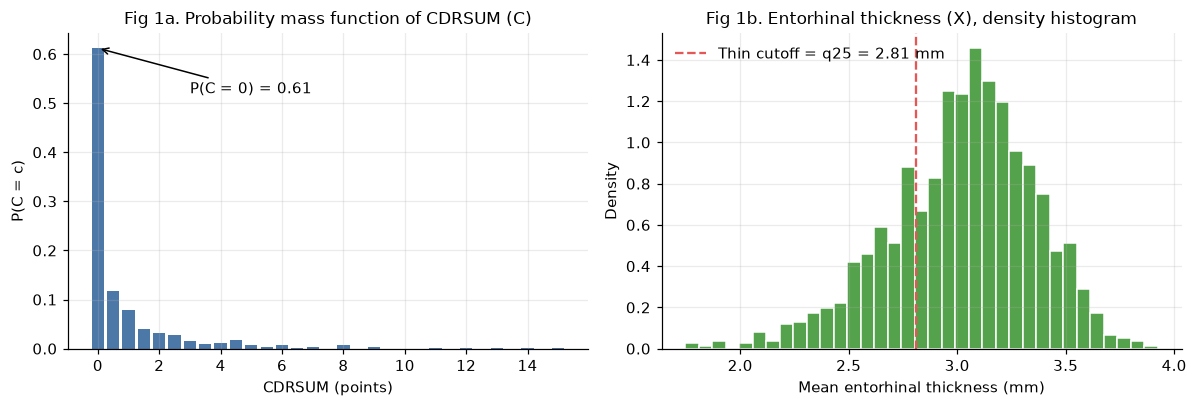

In [9]:
c = df["CDRSUM"].dropna()
x = df["TH_ENTORHINAL"].dropna()
pmf_c = c.value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(pmf_c.index.astype(float), pmf_c.values, width=0.4, color=BLUE)
ax[0].set(title="Fig 1a. Probability mass function of CDRSUM (C)", xlabel="CDRSUM (points)",
          ylabel="P(C = c)")
ax[0].annotate(f"P(C = 0) = {pmf_c.get(0.0, 0):.2f}", xy=(0, pmf_c.get(0.0, 0)),
               xytext=(3, pmf_c.get(0.0, 0) * 0.85), arrowprops=dict(arrowstyle="->"))
ax[1].hist(x, bins=35, density=True, color=GREEN, edgecolor="white")
ax[1].axvline(Q25, color=RED, ls="--", label=f"Thin cutoff = q25 = {Q25:.2f} mm")
ax[1].set(title="Fig 1b. Entorhinal thickness (X), density histogram", xlabel="Mean entorhinal thickness (mm)",
          ylabel="Density")
ax[1].legend(frameon=False)
save_fig("fig1_random_variables")

<div dir="rtl">

**تفسیر.** $C$ یک توزیع «پر از صفر» با دنباله‌ی بلند به راست دارد (بیشتر افراد بدون اختلال‌اند و تعداد کمی نمره‌های بالا دارند). $X$ یک توزیع پیوسته‌ی زنگوله‌مانند است که انتظار می‌رود دنباله‌ی کوتاهی به سمت مقدارهای کم (آتروفی) داشته باشد (فاز ۱). همین تفاوت شکل، پایه‌ی انتخاب‌های بعدی ماست: برای $C$ مدل نرمال مناسب نیست، برای $X$ باید دقیق‌تر بررسی کنیم (بخش ۷).

</div>

<div dir="rtl">

---
# ۳. احتمال حاشیه‌ای و مشترک (تسک ۲ و J.3)

برای دو پیشامد $A$ و $B$ جدول $2\times2$ فراوانی‌ها را می‌سازیم؛ تقسیم همه‌ی خانه‌ها بر $n$ **جدول احتمال مشترک** را می‌دهد. جمع هر سطر و ستون، **احتمال حاشیه‌ای** است:

|  | $B$ | $B^c$ | حاشیه |
|---|---|---|---|
| $A$ | $P(A\cap B)$ | $P(A\cap B^c)$ | $P(A)$ |
| $A^c$ | $P(A^c\cap B)$ | $P(A^c\cap B^c)$ | $P(A^c)$ |
| حاشیه | $P(B)$ | $P(B^c)$ | ۱ |

**ساختار «دو وجهی» (J.3):** پیشامد $A$ از **UDS** (بالینی) و پیشامد $B$ از **MRI** ساخته می‌شود:

- وجه UDS: CDR+، Dx_imp، Dem
- وجه MRI: Thin (انتورینال نازک)

ابتدا جفت اصلی پروژه (CDR+، Thin) را کامل می‌بینیم، بعد همین کار را برای دو پیشامد تشخیصی تکرار می‌کنیم.

</div>

In [6]:
def pair_stats(A, B):
    """همه‌ی احتمال‌های یک جفت پیشامد، روی مجموعه‌ی مشترک افرادی که هر دو برایشان تعریف‌شده است."""
    ok = A.notna() & B.notna()
    a, b = A[ok].astype(bool).to_numpy(), B[ok].astype(bool).to_numpy()
    n = int(ok.sum())
    pA, pB, pAB, pU = a.mean(), b.mean(), (a & b).mean(), (a | b).mean()
    assert np.isclose(pU, pA + pB - pAB), "اصل شمول و عدم شمول برقرار نیست"      # کنترل منطقی
    return dict(n=n, P_A=pA, P_B=pB, P_AB=pAB, P_union=pU,
                P_A_given_B=pAB / pB,        P_A_given_notB=(a & ~b).mean() / (1 - pB),
                P_B_given_A=pAB / pA,        P_B_given_notA=(~a & b).mean() / (1 - pA))

def table_2x2(A, B, nameA, nameB):
    ok = A.notna() & B.notna()
    a, b = A[ok].astype(bool).to_numpy(), B[ok].astype(bool).to_numpy()
    cnt = pd.DataFrame({nameB:          [(a & b).sum(),  (~a & b).sum()],
                        f"not {nameB}": [(a & ~b).sum(), (~a & ~b).sum()]},
                       index=[nameA, f"not {nameA}"])
    n = cnt.values.sum()
    joint_tab = cnt / n
    joint_tab["marginal"] = joint_tab.sum(axis=1)          # حاشیه‌ی سطرها: P(A) و P(A^c)
    joint_tab.loc["marginal"] = joint_tab.sum()            # حاشیه‌ی ستون‌ها: P(B) و P(B^c)؛ گوشه = 1
    return cnt, joint_tab, int(n)

cnt, jt, n_used = table_2x2(CDR_pos, Thin, "CDR+", "Thin")
print(f"جفت اصلی: (CDR+, Thin) — n = {n_used}")
print("\nفراوانی‌ها:");                       display(cnt)
print("\nجدول احتمال مشترک و حاشیه‌ای:");     display(jt)

s = pair_stats(CDR_pos, Thin)
joint(CDR_pos, Thin, "P(CDR+ ∩ Thin)")
prob(CDR_pos, label="P(CDR+)  [all participants with CDRSUM]")
prob(Thin,    label="P(Thin)  [all participants with entorhinal MRI]")
print(f"\nP(CDR+)={s['P_A']:.3f} | P(Thin)={s['P_B']:.3f} | P(CDR+ ∩ Thin)={s['P_AB']:.3f} | "
      f"P(CDR+ ∪ Thin)={s['P_union']:.3f}")
print("اصل شمول و عدم شمول: P(A∪B) = P(A)+P(B)−P(A∩B) برقرار است ✔")

جفت اصلی: (CDR+, Thin) — n = 1224

فراوانی‌ها:


,Thin,not Thin
CDR+,183,288
not CDR+,123,630



جدول احتمال مشترک و حاشیه‌ای:


,Thin,not Thin,marginal
CDR+,0.1495,0.2353,0.3848
not CDR+,0.1005,0.5147,0.6152
marginal,0.2500,0.7500,1.0000



P(CDR+)=0.385 | P(Thin)=0.250 | P(CDR+ ∩ Thin)=0.150 | P(CDR+ ∪ Thin)=0.485
اصل شمول و عدم شمول: P(A∪B) = P(A)+P(B)−P(A∩B) برقرار است ✔


<div dir="rtl">

### جدول مشترکِ چهارگروهه‌ی CDR با Thin
جفت دودویی (CDR+، Thin) اطلاعات گروه‌های شدت را فشرده می‌کند. با گروه‌های چهارتایی فاز ۱ ($0$، $0.5$–$1.5$، $2$–$4.5$، $\ge 5$) جدول مشترک $4\times2$ می‌سازیم؛ هر خانه $P(\text{گروه}\cap\text{Thin})$ است و حاشیه‌ها $P(\text{گروه})$ و $P(\text{Thin})$.

</div>

جدول احتمال مشترک (CDR_group × Thin)، n = 1224


,Thin,not Thin,P(group)
CDR_group,,,
0,0.1005,0.5147,0.6152
0.5-1.5,0.0645,0.1675,0.2320
2-4.5,0.0588,0.0547,0.1136
>=5,0.0261,0.0131,0.0392
P(Thin / not Thin),0.2500,0.7500,1.0000


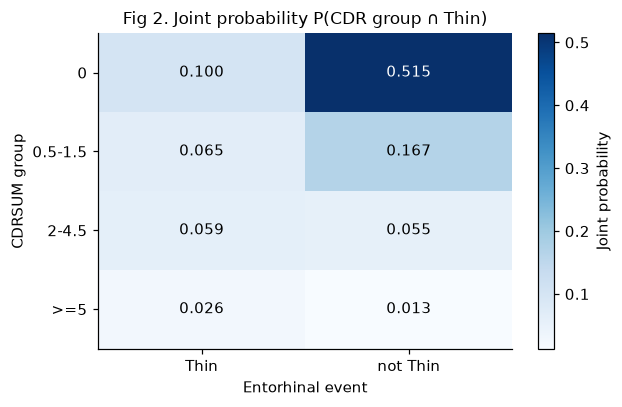

In [7]:
ok = df["CDR_group"].notna() & Thin.notna()
cnt4 = pd.crosstab(df.loc[ok, "CDR_group"], Thin[ok].astype(bool)).reindex(columns=[True, False], fill_value=0)
cnt4.columns = ["Thin", "not Thin"]
n4 = int(cnt4.values.sum())

joint4 = cnt4 / n4
joint4["P(group)"] = joint4.sum(axis=1)
joint4.loc["P(Thin / not Thin)"] = joint4.sum()
print(f"جدول احتمال مشترک (CDR_group × Thin)، n = {n4}")
display(joint4)
assert np.isclose(joint4.iloc[:-1, :2].values.sum(), 1.0)       # مجموع خانه‌ها = 1

# ثبت در جدول احتمال
for g in CDR_LABELS:
    reg(f"P(CDR group {g} ∩ Thin)", cnt4.loc[g, "Thin"], n4)

fig, ax = plt.subplots(figsize=(5.8, 3.8))
im = ax.imshow(joint4.iloc[:-1, :2].values, cmap="Blues", aspect="auto")
ax.set_xticks([0, 1], ["Thin", "not Thin"]); ax.set_yticks(range(4), CDR_LABELS)
for i in range(4):
    for j in range(2):
        v = joint4.iloc[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v > 0.3 else "black")
ax.set(title="Fig 2. Joint probability P(CDR group ∩ Thin)", xlabel="Entorhinal event", ylabel="CDRSUM group")
ax.grid(False); plt.colorbar(im, label="Joint probability")
save_fig("fig2_joint_probability")

<div dir="rtl">

**تفسیر.** هر عدد در شکل ۲ سهم *کل نمونه* است، نه سهم داخل گروه. بنابراین خانه‌ی «گروه ۰ و not Thin» بزرگ است صرفاً چون گروه ۰ بزرگ‌ترین گروه است (حدود ۶۱٪ نمونه). **احتمال مشترک به‌تنهایی برای مقایسه‌ی گروه‌ها مناسب نیست**، چون اندازه‌ی گروه را هم در خود دارد. برای پاسخ به سؤال «در گروه شدیدتر، Thin بیشتر است؟» به احتمال **شرطی** نیاز داریم (بخش ۴).

### دو وجه UDS و MRI: جدول خلاصه برای سه پیشامد UDS
برای هر پیشامد UDS ($U$) و Thin ($T$) هفت عدد گزارش می‌کنیم: سه احتمال حاشیه‌ای/مشترک و چهار احتمال شرطی.

</div>

In [8]:
uds_events = {"CDR+ (CDRSUM>0)": CDR_pos, "Dx_imp (NACCUDSD>=2)": Dx_imp, "Dem (NACCUDSD=4)": Dem}

rows = {}
for name, U in uds_events.items():
    s = pair_stats(U, Thin)
    rows[name] = {"n": s["n"], "P(U)": s["P_A"], "P(T)": s["P_B"], "P(U∩T)": s["P_AB"],
                  "P(U|T)": s["P_A_given_B"], "P(U|not T)": s["P_A_given_notB"],
                  "P(T|U)": s["P_B_given_A"], "P(T|not U)": s["P_B_given_notA"]}
summary_pairs = pd.DataFrame(rows).T
summary_pairs["n"] = summary_pairs["n"].astype(int)
display(summary_pairs)

for name, U in uds_events.items():
    short = name.split(" ")[0]
    joint(U, Thin, f"P({short} ∩ Thin)")
    prob(U,        label=f"P({short})  [all participants]")

,n,P(U),P(T),P(U∩T),P(U|T),P(U|not T),P(T|U),P(T|not U)
CDR+ (CDRSUM>0),1224,0.3848,0.2500,0.1495,0.5980,0.3137,0.3885,0.1633
Dx_imp (NACCUDSD>=2),1224,0.3121,0.2500,0.1373,0.5490,0.2331,0.4398,0.1639
Dem (NACCUDSD=4),1224,0.1062,0.2500,0.0662,0.2647,0.0534,0.6231,0.2057


<div dir="rtl">

**نحوه‌ی خواندن جدول:**

- `P(U|T)` در برابر `P(U|not T)`: اگر $P(U\mid T)\gg P(U\mid T^c)$، یعنی شناختنِ «انتورینال نازک» احتمال پیشامد بالینی را بالا می‌برد.
- `P(T|U)` در برابر `P(T|not U)`: همان رابطه از زاویه‌ی مقابل؛ این‌ها با نسخه‌ی قبلی **برابر نیستند** (در بخش ۴ دلیلش را می‌بینیم).
- هر ردیف روی مجموعه‌ی مشترک افراد محاسبه شده، پس ستون `n` فرق می‌کند فقط اگر گمشدگی متفاوتی داشته باشند (اینجا `NACCUDSD` و `CDRSUM` کامل‌اند و تفاوت فقط از گمشدگی MRI است).

</div>

<div dir="rtl">

---
# ۴. احتمال شرطی (تسک ۳ و J.1)

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}$$

شرط کردن یعنی **دنیا را کوچک می‌کنیم**: فقط افرادی را نگه می‌داریم که $B$ برایشان رخ داده و در همان گروه، سهم $A$ را می‌شماریم. اگر $P(A\mid B)\neq P(A)$ باشد، دانستنِ $B$ اطلاعاتی دربارهٔ $A$ می‌دهد.

برای مقایسه‌ی دو احتمال شرطی از دو معیار توصیفی استفاده می‌کنیم:

- **تفاضل:** $P(A\mid B)-P(A\mid B^c)$
- **نسبت (lift):** $\dfrac{P(A\mid B)}{P(A\mid B^c)}$ — عدد ۱ یعنی «بی‌اثر»

## ۴.۱ شدت بالینی و احتمال انتورینال نازک
مستقیم‌ترین پرسش پروژه به زبان احتمال: **با بالا رفتن شدت CDRSUM، احتمال Thin چطور تغییر می‌کند؟**

</div>

In [9]:
def n_of(G, S):
    """تعداد افراد گروه G (که پیشامد S هم برایشان تعریف‌شده)."""
    ok = G.notna() & S.notna()
    return int(G[ok].astype(bool).sum())

p_thin = prob(Thin)
print(f"احتمال بی‌قید و شرط: P(Thin) = {p_thin:.3f}\n")

rows = []
for g in CDR_LABELS:
    G = make_event(df["CDR_group"] == g, "CDRSUM")
    rows.append({"CDR group": g, "n": n_of(G, Thin),
                 "P(Thin | group)": prob(Thin, G, label=f"P(Thin | CDR group {g})")})
t41 = pd.DataFrame(rows).set_index("CDR group")
t41["ratio to P(Thin)"] = t41["P(Thin | group)"] / p_thin
display(t41)

# ---- دو گروه ساده: CDR+ در برابر CDR=0
a = prob(Thin, CDR_pos,  label="P(Thin | CDR+)")
b = prob(Thin, ~CDR_pos, label="P(Thin | CDR=0)")
print(f"\nP(Thin | CDR+)  = {a:.3f}")
print(f"P(Thin | CDR=0) = {b:.3f}")
print(f"تفاضل = {a - b:+.3f} | نسبت (lift) = {a / b:.2f}")
print(f"→ در افراد دارای CDRSUM>0 احتمال انتورینال نازک {a / b:.1f} برابر افراد با CDRSUM=0 است.")

# ---- شرط‌گذاری در جهت مقابل: این دو برابر نیستند
c1 = prob(CDR_pos, Thin,  label="P(CDR+ | Thin)")
c2 = prob(CDR_pos, ~Thin, label="P(CDR+ | not Thin)")
print(f"\nجهت مقابل:  P(CDR+ | Thin) = {c1:.3f} | P(CDR+ | not Thin) = {c2:.3f}")
print(f"توجه: P(Thin | CDR+) = {a:.3f}  ≠  P(CDR+ | Thin) = {c1:.3f}")

احتمال بی‌قید و شرط: P(Thin) = 0.250



,n,P(Thin | group),ratio to P(Thin)
CDR group,,,
0,753,0.1633,0.6534
0.5-1.5,284,0.2782,1.1127
2-4.5,139,0.5180,2.0719
>=5,48,0.6667,2.6667



P(Thin | CDR+)  = 0.389
P(Thin | CDR=0) = 0.163
تفاضل = +0.225 | نسبت (lift) = 2.38
→ در افراد دارای CDRSUM>0 احتمال انتورینال نازک 2.4 برابر افراد با CDRSUM=0 است.

جهت مقابل:  P(CDR+ | Thin) = 0.598 | P(CDR+ | not Thin) = 0.314
توجه: P(Thin | CDR+) = 0.389  ≠  P(CDR+ | Thin) = 0.598


<div dir="rtl">

**تفسیر.**

- جدول ۴.۱ نشان می‌دهد با رفتن از گروه ۰ به گروه‌های شدیدتر، $P(\text{Thin}\mid\text{گروه})$ چگونه تغییر می‌کند. انتظار (از فاز ۱ که میانه‌ی ضخامت از ۳٫۱۱ به ۲٫۶۹ میلی‌متر می‌رسید) یک **روند صعودی** است: هرچه گروه شدیدتر، احتمال Thin بیشتر. اگر روند یکنواخت نبود، آن را همان‌طور که هست گزارش می‌کنیم (گروه $\ge5$ فقط ۴۸ نفر دارد و برآوردش ناپایدارتر است).
- ستون `ratio to P(Thin)` می‌گوید شرط‌گذاری روی هر گروه، احتمال Thin را چند برابرِ مقدار بی‌قید و شرط می‌کند؛ مقدار ۱ یعنی هیچ تغییری.
- **عدم تقارن شرطی:** $P(\text{Thin}\mid\text{CDR+})$ و $P(\text{CDR+}\mid\text{Thin})$ دو سؤال متفاوت‌اند. اولی «از میان بیماران، چند درصد انتورینال نازک دارند؟» و دومی «از میان دارندگان انتورینال نازک، چند درصد بیمارند؟». تفاوت‌شان از مخرج‌ها می‌آید (اندازه‌ی گروه CDR+ با گروه Thin یکی نیست). خلط این دو، «مغالطه‌ی وکیل‌مدافع» (transposed conditional) نام دارد.

</div>

<div dir="rtl">

## ۴.۲ وضعیت شناختی با گروه‌بندی بر پایه‌ی MRI (J.1)

**وضعیت‌های تشخیصی (UDS):**
- **Dx_imp:** تشخیصِ غیرطبیعی ($\text{NACCUDSD}\ge2$)
- **Dem:** زوال عقل ($\text{NACCUDSD}=4$)

**گروه‌بندی‌ها** (دست‌کم یکی باید از MRI یا ترکیب UDS و MRI ساخته شود — اینجا هر سه نوع را داریم):

1. Thin در برابر not Thin → **فقط MRI**
2. چهار چارک ضخامت انتورینال → **فقط MRI**
3. ترکیب Thin × Old → **ترکیب UDS (سن) و MRI**

گروه‌بندی ۲ به ما اجازه می‌دهد ببینیم احتمال وضعیت شناختی در طول محور ضخامت **یکنواخت** تغییر می‌کند یا فقط در دُم پایین (یک «آستانه‌ای بودن» احتمالی).

</div>

In [10]:
def cond_table(groups, statuses, register=True):
    """برای هر گروه (پیشامد) و هر وضعیت: P(status | group). ستون n = اندازه‌ی گروه."""
    rows = []
    for gname, G in groups.items():
        row = {"Group": gname}
        first_status = next(iter(statuses.values()))
        row["n"] = n_of(G, first_status)
        for sname, S in statuses.items():
            row[f"P({sname} | group)"] = prob(S, G, label=f"P({sname} | {gname})" if register else None)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Group")

df["ENT_Q"] = pd.qcut(df["TH_ENTORHINAL"], 4, labels=["Q1 (thinnest)", "Q2", "Q3", "Q4 (thickest)"])
statuses = {"Dx_imp": Dx_imp, "Dem": Dem}

# ---- گروه‌بندی ۱: فقط MRI
g1 = {"Thin": Thin, "not Thin": ~Thin}
t_g1 = cond_table(g1, statuses)
# ---- گروه‌بندی ۲: چارک‌های ضخامت
g2 = {f"Entorhinal {q}": make_event(df["ENT_Q"] == q, "TH_ENTORHINAL") for q in df["ENT_Q"].cat.categories}
t_g2 = cond_table(g2, statuses)
# ---- گروه‌بندی ۳: ترکیب UDS (سن) و MRI
g3 = {"Thin & Old":         AND(Thin, Old),
      "Thin & not Old":     AND(Thin, ~Old),
      "not Thin & Old":     AND(~Thin, Old),
      "not Thin & not Old": AND(~Thin, ~Old)}
t_g3 = cond_table(g3, statuses)

for title, t in [("۱) Thin در برابر not Thin (فقط MRI)", t_g1),
                 ("۲) چارک‌های ضخامت انتورینال (فقط MRI)", t_g2),
                 ("۳) Thin × Old (ترکیب UDS و MRI)", t_g3)]:
    print(f"\n{title}"); display(t)

pd_t, pd_nt = t_g1.loc["Thin", "P(Dx_imp | group)"], t_g1.loc["not Thin", "P(Dx_imp | group)"]
print(f"\nP(Dx_imp | Thin) = {pd_t:.3f} در برابر P(Dx_imp | not Thin) = {pd_nt:.3f}  → نسبت {pd_t / pd_nt:.2f}")
print(f"P(Dem | Thin)    = {t_g1.loc['Thin', 'P(Dem | group)']:.3f} در برابر "
      f"P(Dem | not Thin) = {t_g1.loc['not Thin', 'P(Dem | group)']:.3f}")


۱) Thin در برابر not Thin (فقط MRI)


/tmp/ipykernel_21123/172320347.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["ENT_Q"] = pd.qcut(df["TH_ENTORHINAL"], 4, labels=["Q1 (thinnest)", "Q2", "Q3", "Q4 (thickest)"])


,n,P(Dx_imp | group),P(Dem | group)
Group,,,
Thin,306,0.5490,0.2647
not Thin,918,0.2331,0.0534



۲) چارک‌های ضخامت انتورینال (فقط MRI)


,n,P(Dx_imp | group),P(Dem | group)
Group,,,
Entorhinal Q1 (thinnest),306,0.5490,0.2647
Entorhinal Q2,306,0.2810,0.0882
Entorhinal Q3,306,0.2320,0.0359
Entorhinal Q4 (thickest),306,0.1863,0.0359



۳) Thin × Old (ترکیب UDS و MRI)


,n,P(Dx_imp | group),P(Dem | group)
Group,,,
Thin & Old,184,0.5761,0.2663
Thin & not Old,122,0.5082,0.2623
not Thin & Old,362,0.3039,0.0580
not Thin & not Old,556,0.1871,0.0504



P(Dx_imp | Thin) = 0.549 در برابر P(Dx_imp | not Thin) = 0.233  → نسبت 2.36
P(Dem | Thin)    = 0.265 در برابر P(Dem | not Thin) = 0.053


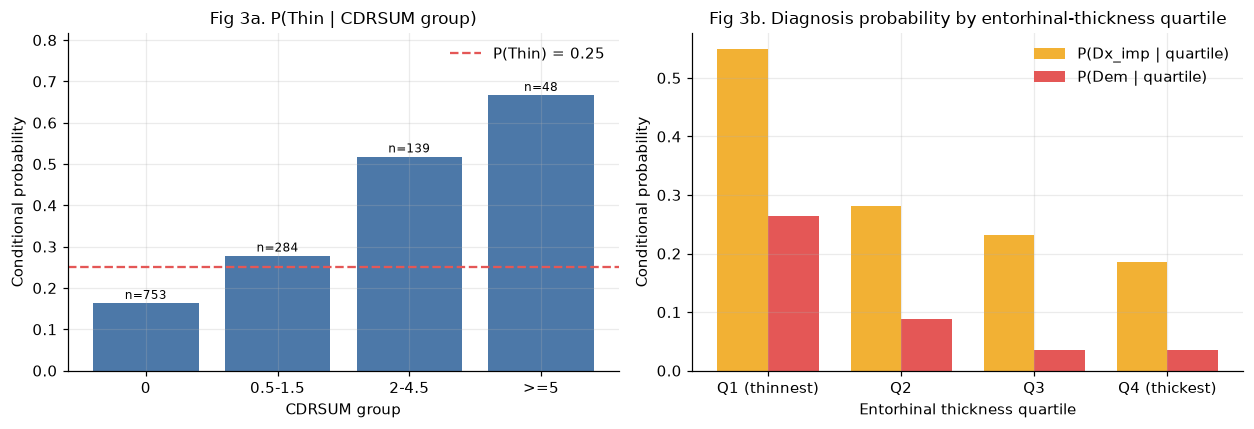

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))

# (الف) P(Thin | CDR group)
bars = ax[0].bar(t41.index, t41["P(Thin | group)"], color=BLUE)
ax[0].axhline(p_thin, color=RED, ls="--", label=f"P(Thin) = {p_thin:.2f}")
for rect, n in zip(bars, t41["n"]):
    ax[0].text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.01, f"n={n}", ha="center", fontsize=8)
ax[0].set(title="Fig 3a. P(Thin | CDRSUM group)", xlabel="CDRSUM group", ylabel="Conditional probability",
          ylim=(0, min(1, t41["P(Thin | group)"].max() + 0.15)))
ax[0].legend(frameon=False)

# (ب) P(وضعیت | چارک ضخامت)
xpos = np.arange(len(t_g2))
w = 0.38
ax[1].bar(xpos - w / 2, t_g2["P(Dx_imp | group)"], w, color=GOLD, label="P(Dx_imp | quartile)")
ax[1].bar(xpos + w / 2, t_g2["P(Dem | group)"],    w, color=RED,  label="P(Dem | quartile)")
ax[1].set_xticks(xpos, [i.replace("Entorhinal ", "") for i in t_g2.index])
ax[1].set(title="Fig 3b. Diagnosis probability by entorhinal-thickness quartile",
          xlabel="Entorhinal thickness quartile", ylabel="Conditional probability")
ax[1].legend(frameon=False)
save_fig("fig3_conditional_probability")

<div dir="rtl">

**تفسیر.**

- شکل ۳الف همان روندِ بخش ۴.۱ را تصویری می‌کند؛ خط چین قرمز احتمال بی‌قید و شرطِ Thin است. میله‌های بالای خط یعنی «در آن گروه، Thin بیشتر از حالت عادی است».
- شکل ۳ب نشان می‌دهد وضعیت شناختی چگونه با چارک ضخامت عوض می‌شود. اگر احتمال فقط در چارک ۱ (نازک‌ترین) بالا برود و در سه چارک دیگر تقریباً ثابت بماند، رابطه بیشتر «آستانه‌ای» است تا خطی؛ اگر پله‌پله پایین بیاید، رابطه تدریجی است. این را از خود نمودار بخوانید.
- جدول گروه‌بندی ۳ دو منبع اطلاعات را ترکیب می‌کند (سن از UDS، ضخامت از MRI). اگر در هر دو ردیفِ سنی، Thin احتمال وضعیت شناختی را بالا ببرد، یعنی اثر Thin فقط بازتاب سن نیست.

## ۴.۳ کنترل سن با شرط‌گذاری (طبقه‌بندی)
در فاز ۱ دیدیم افراد بیمارتر حدود ۴ سال مسن‌ترند و ضخامت هم با سن کم می‌شود؛ پس سن می‌تواند «رابطه‌ی ظاهری» بسازد. یک راه ساده‌ی احتمالی برای مهار آن: **درون هر گروه سنی** احتمال Thin را برای CDR+ و CDR=0 جدا حساب کنیم. اگر شکاف در هر گروه سنی باقی بماند، سن به‌تنهایی توضیح‌دهنده‌ی آن نیست. (این روش توصیفی است و جایگزین مدل‌سازی فاز بعد نمی‌شود.)

</div>

In [12]:
rows = []
for band in df["AGE_band"].cat.categories:
    Bd = make_event(df["AGE_band"] == band, "NACCAGE")
    pos, neg = AND(CDR_pos, Bd), AND(~CDR_pos, Bd)
    p1, p0 = prob(Thin, pos), prob(Thin, neg)
    rows.append({"Age band": band, "n CDR+": n_of(pos, Thin), "n CDR=0": n_of(neg, Thin),
                 "P(Thin | CDR+, band)": p1, "P(Thin | CDR=0, band)": p0,
                 "difference": p1 - p0, "lift": p1 / p0 if p0 else np.nan})
t43 = pd.DataFrame(rows).set_index("Age band")
display(t43)
print("هشدار: در برخی گروه‌های سنی تعداد افراد کم است؛ نسبت‌ها را با توجه به ستون‌های n بخوانید.")

,n CDR+,n CDR=0,"P(Thin | CDR+, band)","P(Thin | CDR=0, band)",difference,lift
Age band,,,,,,
<60,51,122,0.4314,0.0738,0.3576,5.8475
60-69,158,347,0.2722,0.1383,0.1338,1.9674
70-79,211,238,0.4265,0.1975,0.2291,2.1599
>=80,51,46,0.5490,0.4130,0.1360,1.3292


هشدار: در برخی گروه‌های سنی تعداد افراد کم است؛ نسبت‌ها را با توجه به ستون‌های n بخوانید.


<div dir="rtl">

**تفسیر.** اگر `difference` در همه‌ی (یا بیشترِ) گروه‌های سنی مثبت باشد، شکافِ Thin بین CDR+ و CDR=0 «فقط به‌خاطر سن» نیست. ولی چون گروه‌های سنی خودشان پهن‌اند (مثلاً ۷۰–۷۹ سال) هنوز مقداری سنِ باقی‌مانده هست؛ پس این جدول **شاهدِ سازگار** است، نه اثبات حذف اثر سن. حذف کاملِ سن به مدل‌سازی (فاز ۴) می‌رسد.

## ۴.۴ حساسیت نتیجه به تعریف «نازک»
چون مرز Thin انتخابی است، همان محاسبه را برای سه مرز می‌کنیم: دهک اول، چارک اول (انتخاب اصلی) و میانه. اگر جهت و اندازه‌ی نتیجه تقریباً ثابت بماند، یافته به این انتخاب وابسته نیست.

</div>

In [14]:
rows = []
for q in (0.10, 0.25, 0.50):
    thr = df["TH_ENTORHINAL"].quantile(q)
    Tq = make_event(df["TH_ENTORHINAL"] <= thr, "TH_ENTORHINAL")
    p1, p0 = prob(Tq, CDR_pos), prob(Tq, ~CDR_pos)
    rows.append({"Cutoff quantile": q, "Cutoff (mm)": thr,
                 "P(Thin | CDR+)": p1, "P(Thin | CDR=0)": p0, "lift": p1 / p0,
                 "P(Dem | Thin)": prob(Dem, Tq), "P(Dem | not Thin)": prob(Dem, ~Tq)})
t44 = pd.DataFrame(rows).set_index("Cutoff quantile")
display(t44)

,Cutoff (mm),P(Thin | CDR+),P(Thin | CDR=0),lift,P(Dem | Thin),P(Dem | not Thin)
Cutoff quantile,,,,,,
0.1000,2.5696,0.1975,0.0398,4.9561,0.3659,0.0772
0.2500,2.8117,0.3885,0.1633,2.3786,0.2647,0.0534
0.5000,3.0597,0.6369,0.4143,1.5372,0.1765,0.0359


<div dir="rtl">

**تفسیر.** با سخت‌گیرانه‌تر شدن مرز (دهک اول) Thin کم‌یاب‌تر می‌شود و نسبت‌ها معمولاً بزرگ‌تر ولی ناپایدارتر می‌شوند (تعدادِ کمتر)؛ با مرز میانه نسبت‌ها به ۱ نزدیک‌تر می‌شوند چون گروه Thin نیمی از نمونه را در بر می‌گیرد. نکته‌ی مهم **جهت** است: اگر برای هر سه مرز $P(\text{Thin}\mid\text{CDR+})>P(\text{Thin}\mid\text{CDR=0})$ باشد، نتیجه به انتخاب مرز حساس نیست.

</div>

<div dir="rtl">

---
# ۵. استقلال (تسک ۴)

دو پیشامد $A$ و $B$ **مستقل‌اند** اگر

$$P(A\cap B)=P(A)\,P(B)\quad\Longleftrightarrow\quad P(A\mid B)=P(A)$$

یعنی دانستنِ $B$ چیزی دربارهٔ $A$ نمی‌گوید. در داده‌ی واقعی هیچ‌وقت تساوی «دقیق» برقرار نیست (نوسان نمونه‌گیری)، پس سؤال درست این است: **آیا اختلاف بین مقدار مشاهده‌شده و مقدار مورد انتظار زیر استقلال، در حدّ نوسان معمولِ نمونه‌ی ما است؟**


جفت‌ها را عمداً متنوع انتخاب کرده‌ایم: بعضی را «انتظار داریم» وابسته باشند (CDR و ضخامت)، بعضی را «انتظار داریم» نزدیک به مستقل (جنس و ضخامت).

</div>

In [15]:
pairs = [("CDR+", CDR_pos, "Thin", Thin), ("CDR>=2", CDR_ge2, "Thin", Thin), ("Dem", Dem, "Thin", Thin),
         ("Fem", Fem, "Thin", Thin), ("Fem", Fem, "CDR+", CDR_pos),
         ("Old", Old, "Thin", Thin), ("Old", Old, "CDR+", CDR_pos),
         ("HiEdu", HiEdu, "Thin", Thin), ("HiEdu", HiEdu, "CDR+", CDR_pos)]

rows = []
for nA, A, nB, B in pairs:
    s = pair_stats(A, B)
    expected = s["P_A"] * s["P_B"]
    se = math.sqrt(expected * (1 - expected) / s["n"])
    rows.append({"Pair (A, B)": f"{nA}, {nB}", "n": s["n"], "P(A)": s["P_A"], "P(B)": s["P_B"],
                 "P(A∩B) observed": s["P_AB"], "P(A)P(B) expected": expected,
                 "difference": s["P_AB"] - expected, "lift = obs/exp": s["P_AB"] / expected,
                 "|diff| / SE (rough)": abs(s["P_AB"] - expected) / se})
t5 = pd.DataFrame(rows).set_index("Pair (A, B)")
t5["Verdict (rough)"] = np.where(t5["|diff| / SE (rough)"] < 2, "compatible with independence", "NOT compatible")
display(t5)

r0 = t5.iloc[0]                                                  # جفت اصلی (CDR+, Thin)
reg_value("P(CDR+)·P(Thin)  [expected joint under independence]", r0["P(A)"] * r0["P(B)"])

,n,P(A),P(B),P(A∩B) observed,P(A)P(B) expected,difference,lift = obs/exp,|diff| / SE (rough),Verdict (rough)
"Pair (A, B)",,,,,,,,,
"CDR+, Thin",1224,0.3848,0.2500,0.1495,0.0962,0.0533,1.5541,6.3251,NOT compatible
"CDR>=2, Thin",1224,0.1528,0.2500,0.0850,0.0382,0.0468,2.2246,8.5377,NOT compatible
"Dem, Thin",1224,0.1062,0.2500,0.0662,0.0266,0.0396,2.4923,8.6227,NOT compatible
"Fem, Thin",1224,0.6013,0.2500,0.1520,0.1503,0.0016,1.0109,0.1600,compatible with independence
"Fem, CDR+",1237,0.5982,0.3880,0.2086,0.2321,-0.0236,0.8985,1.9629,compatible with independence
"Old, Thin",1224,0.4461,0.2500,0.1503,0.1115,0.0388,1.3480,4.3132,NOT compatible
"Old, CDR+",1237,0.4462,0.3880,0.2167,0.1732,0.0435,1.2512,4.0430,NOT compatible
"HiEdu, Thin",1222,0.7152,0.2496,0.1735,0.1785,-0.0050,0.9718,0.4588,compatible with independence
"HiEdu, CDR+",1235,0.7166,0.3879,0.2640,0.2779,-0.0140,0.9497,1.0958,compatible with independence


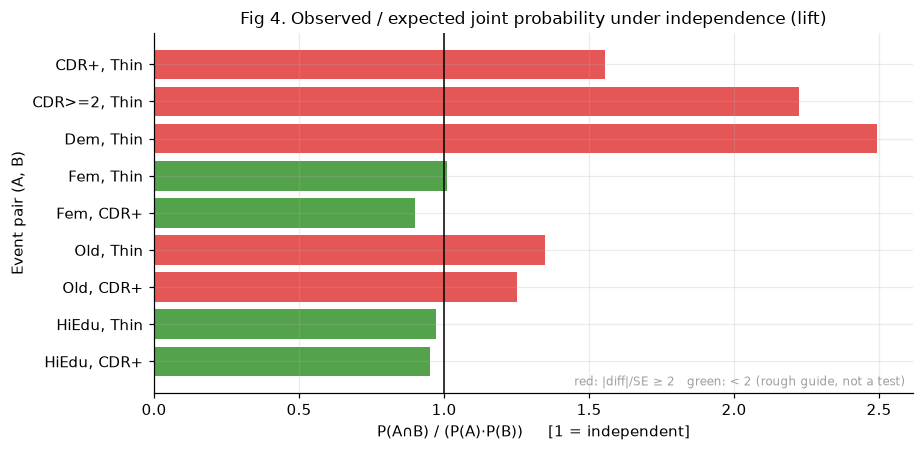

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
colors = [RED if v >= 2 else GREEN for v in t5["|diff| / SE (rough)"]]
ax.barh(t5.index[::-1], t5["lift = obs/exp"][::-1], color=colors[::-1])
ax.axvline(1, color="black", lw=1)
ax.set(title="Fig 4. Observed / expected joint probability under independence (lift)",
       xlabel="P(A∩B) / (P(A)·P(B))     [1 = independent]", ylabel="Event pair (A, B)")
ax.text(0.99, 0.02, "red: |diff|/SE ≥ 2   green: < 2 (rough guide, not a test)",
        transform=ax.transAxes, ha="right", fontsize=8, color=GREY)
save_fig("fig4_independence_lift")

<div dir="rtl">

**تفسیر.** (مقادیر دقیق را از جدول بخوانید؛ این‌ها الگوهای مورد انتظار بر پایه‌ی فاز ۱ هستند.)

- **CDR+ و Thin:** انتظار داریم lift قابل‌توجهی بزرگ‌تر از ۱ باشد؛ یعنی هم‌رخدادیِ «بیماری بالینی و انتورینال نازک» بیش از حدِ مورد انتظار زیر استقلال است. این همان شکل احتمالیِ سؤال پروژه است.
- **Fem و Thin / Fem و CDR+:** در فاز ۱ ضخامت بین زن و مرد تقریباً یکی بود؛ پس انتظار داریم lift نزدیک ۱ باشد.
- **Old با Thin و CDR+:** سن هم با ضخامت و هم با شدت بالینی همبسته است؛ این همان هم‌آمیختگی (confounding) است که در فاز ۱ هشدار دادیم.
- **HiEdu:** تحصیلات بالا ممکن است با شدت بالینی رابطه‌ی ضعیفی داشته باشد (ذخیره‌ی شناختی)؛ اگر lift کمتر از ۱ بود جهت آن را گزارش کنید، ولی بدون ادعای علّی.

**استقلال شرطی.** جدول ۴.۳ یک پرسش دقیق‌تر را هم جواب می‌دهد: آیا Thin و CDR+ **به شرط سن** هم وابسته‌اند؟ اگر $P(\text{Thin}\mid\text{CDR+},\text{band})\neq P(\text{Thin}\mid\text{CDR=0},\text{band})$ در هر گروه سنی، وابستگی با ثابت نگه داشتن سن هم باقی است. استقلال *حاشیه‌ای* (جدول بالا) و استقلال *شرطی* (جدول ۴.۳) دو مفهوم جدا هستند: دو پیشامد می‌توانند حاشیه‌ای وابسته ولی به شرط یک متغیر سوم مستقل باشند (مثلاً وقتی همه‌ی رابطه از سن آمده باشد) و برعکس.

</div>

<div dir="rtl">

---
# ۶. توزیع گسسته و مدل دوجمله‌ای (تسک ۵)

## ۶.۱ چه وقت دوجمله‌ای مدل معقولی است؟
$K\sim\text{Binomial}(m,p)$ وقتی چهار شرط برقرار باشد:

1. **دودویی:** هر «آزمایش» فقط دو نتیجه دارد (موفقیت/شکست).
2. **تعداد ثابت:** $m$ از قبل معلوم است.
3. **احتمال ثابت:** احتمال موفقیت در همه‌ی آزمایش‌ها یکی است ($p$).
4. **استقلال:** نتیجه‌ی هر آزمایش روی بقیه اثر ندارد.

$$P(K=k)=\binom{m}{k}p^k(1-p)^{m-k},\qquad E[K]=mp,\qquad \mathrm{Var}(K)=mp(1-p)$$

## ۶.۲ سناریوی ما
فرض کنید **۲۰ نفر را به‌تصادف و بدون جایگزینی** از ۱۲۳۷ نفر برمی‌داریم و $K$ = تعداد افرادِ CDR+ ($\text{CDRSUM}>0$) میان آن‌ها. کدام شرط‌ها برقرارند؟

- دودویی و $m=20$ ثابت: ✔
- احتمال ثابت: تقریباً ✔ — چون از یک جامعه‌ی متناهی **بدون جایگزینی** برمی‌داریم، احتمال بعد از هر برداشت کمی عوض می‌شود. دقیقاً این وضعیت توزیع **ابرهندسی** است، ولی وقتی $m\ll N$ باشد ($20\ll1222$) دوجمله‌ای تقریب بسیار خوبی است. ضریب تصحیح واریانس $\frac{N-m}{N-1}$ است که اینجا نزدیک ۱ می‌شود.
- استقلال: تقریباً ✔ به همان دلیل.

پس سه مدل را مقایسه می‌کنیم: **دوجمله‌ای** (تقریبی)، **ابرهندسی** (دقیق برای این سناریو) و **شبیه‌سازی** (۲۰٬۰۰۰ بار نمونه‌گیری واقعی از همین داده).

</div>

In [17]:
M_SAMPLE, N_SIM = 20, 20_000

a_all = CDR_pos.dropna().astype(bool).to_numpy()       # آرایه‌ی 0/1 پیشامد CDR+
N, S_ = len(a_all), int(a_all.sum())
p_hat = S_ / N
print(f"جامعه‌ی متناهی: N = {N}، تعداد CDR+ = {S_}، p̂ = {p_hat:.4f}")

def binom_pmf(k, n, p):
    return math.comb(n, k) * p**k * (1 - p)**(n - k)

def hyper_pmf(k, N, S, n):
    return math.comb(S, k) * math.comb(N - S, n - k) / math.comb(N, n)

ks = np.arange(M_SAMPLE + 1)
pmf_bin = np.array([binom_pmf(k, M_SAMPLE, p_hat) for k in ks])
pmf_hyp = np.array([hyper_pmf(k, N, S_, M_SAMPLE) for k in ks])
sims = np.array([a_all[RNG.choice(N, M_SAMPLE, replace=False)].sum() for _ in range(N_SIM)])
pmf_sim = np.bincount(sims, minlength=M_SAMPLE + 1) / N_SIM

t6 = pd.DataFrame({"k": ks, "Binomial(20, p̂)": pmf_bin, "Hypergeometric (exact)": pmf_hyp,
                   f"Simulation ({N_SIM:,} draws)": pmf_sim}).set_index("k")
display(t6)

print("\nمقایسه‌ی ممان‌ها:")
def pmf_moments(pmf_):
    mean_ = (ks * pmf_).sum()
    return mean_, ((ks - mean_) ** 2 * pmf_).sum()

m_b, v_b = pmf_moments(pmf_bin)
m_h, v_h = pmf_moments(pmf_hyp)
mom = pd.DataFrame({"mean": [m_b, m_h, sims.mean()], "variance": [v_b, v_h, sims.var()]},
                   index=["Binomial", "Hypergeometric", "Simulation"])
mom["theory"] = [f"m·p = {M_SAMPLE * p_hat:.3f}; m·p·(1-p) = {M_SAMPLE * p_hat * (1 - p_hat):.3f}",
                 f"variance × (N-m)/(N-1) = {M_SAMPLE * p_hat * (1 - p_hat) * (N - M_SAMPLE) / (N - 1):.3f}", "—"]
display(mom)

tv = 0.5 * np.abs(pmf_bin - pmf_hyp).sum()
print(f"\nفاصله‌ی تغییرات کل (Binomial vs Hypergeometric) = {tv:.4f}")
print(f"P(K ≥ 10): دوجمله‌ای = {pmf_bin[10:].sum():.4f} | ابرهندسی = {pmf_hyp[10:].sum():.4f} | شبیه‌سازی = {pmf_sim[10:].sum():.4f}")
reg_value("P(K >= 10), K ~ Binomial(20, p̂)  [model]", pmf_bin[10:].sum())
reg_value("P(K >= 10), K ~ Hypergeometric  [exact]", pmf_hyp[10:].sum())

جامعه‌ی متناهی: N = 1237، تعداد CDR+ = 480، p̂ = 0.3880


,"Binomial(20, p̂)",Hypergeometric (exact),"Simulation (20,000 draws)"
k,,,
0,0.0001,0.0000,0.0000
1,0.0007,0.0006,0.0003
2,0.0041,0.0039,0.0034
3,0.0158,0.0153,0.0152
4,0.0425,0.0418,0.0394
5,0.0862,0.0857,0.0854
6,0.1367,0.1370,0.1370
7,0.1734,0.1746,0.1729
8,0.1786,0.1801,0.1830



مقایسه‌ی ممان‌ها:


,mean,variance,theory
Binomial,7.7607,4.7493,m·p = 7.761; m·p·(1-p) = 4.749
Hypergeometric,7.7607,4.6763,variance × (N-m)/(N-1) = 4.676
Simulation,7.7750,4.5654,—



فاصله‌ی تغییرات کل (Binomial vs Hypergeometric) = 0.0039
P(K ≥ 10): دوجمله‌ای = 0.2109 | ابرهندسی = 0.2091 | شبیه‌سازی = 0.2083


<div dir="rtl">

**تفسیر.** سه ستون تقریباً بر هم منطبق‌اند و فاصله‌ی تغییرات کل بسیار کوچک است: برای نمونه‌های کوچک از یک جامعه‌ی بزرگ، **دوجمله‌ای مدل معقولی است**. واریانس ابرهندسی کمی کمتر از دوجمله‌ای است (ضریب $\frac{N-m}{N-1}\approx0.985$) چون «بدون جایگزینی» تنوع را کمی کم می‌کند.

> **قید مهم:** این تقریب برای **نمونه‌گیریِ تصادفی از همین ۱۲۳۷ نفر** درست است. اینکه نمونه‌ی ۱۲۳۷نفره خودش نماینده‌ی جامعه‌ی عمومی باشد، ادعای جداگانه‌ای است و نداریم (داوطلبانِ مراکز تحقیقاتی‌اند).

## ۶.۳ جایی که دوجمله‌ای معقول **نیست**: شمارش آیتم‌های IADL برای هر نفر
هر نفر ۱۰ آیتم IADL دارد (توانایی در کارهای روزمره). تعریف کنیم $J$ = تعداد آیتم‌هایی که **مختل** هستند (نمره‌ی $\ge1$). وسوسه‌انگیز است که بگوییم $J\sim\text{Binomial}(10,p)$ — ولی:

- **احتمال ثابت ✘:** آیتم‌ها دشواری یکسان ندارند؛ مثلاً در فاز ۱ دیدیم آیتم REMDATES (یادآوری قرارها) با حدود ۲۱٪ بیشترین اختلال را دارد و بقیه‌ی آیتم‌ها سهم‌های متفاوتی دارند.
- **استقلال ✘:** کسی که در مدیریت مالی مشکل دارد، احتمالاً در پر کردن مالیات هم مشکل دارد؛ آیتم‌های یک نفر **هم‌بسته**‌اند، چون همه از یک عامل مشترک (شدت بیماری) تأثیر می‌گیرند.

اگر آیتم‌ها مستقل ولی با احتمال‌های متفاوت $p_i$ بودند، واریانس $\sum p_i(1-p_i)$ می‌شد (کمتر یا مساوی واریانس دوجمله‌ای با میانگین $\bar p$). اما برای هر مجموعه‌ی دلخواه از متغیرهای صفر و یک

$$\mathrm{Var}(J)=\sum_i p_i(1-p_i)+\sum_{i\neq j}\mathrm{Cov}(Z_i,Z_j)$$

پس اگر هم‌پراکنشی‌ها مثبت باشند، واریانس واقعی **بزرگ‌تر** از هر دو مدل است («پراکندگی بیش‌ازحد» یا overdispersion). این را از داده می‌سنجیم.

> **یادآوری:** در فاز ۱ دیدیم کدگذاری IADL هنوز با کتابچه‌ی NACC تأیید نشده و داده قبلاً impute شده است. بنابراین از IADL اینجا فقط به‌عنوان **مثال آموزشیِ نقض فرض‌های دوجمله‌ای** استفاده می‌کنیم، نه برای نتیجه‌گیری دربارهٔ پروژه.

</div>

In [18]:
IADL = ["BILLS", "TAXES", "SHOPPING", "GAMES", "STOVE", "MEALPREP", "EVENTS", "PAYATTN", "REMDATES", "TRAVEL"]

complete = df[IADL].notna().all(axis=1)
Z = (df.loc[complete, IADL] >= 1).astype(int)             # Z_i = 1 اگر آیتم i مختل باشد
J_obs = Z.sum(axis=1)                                      # J = تعداد آیتم‌های مختل
p_i = Z.mean()
p_bar = p_i.mean()
print(f"افراد با هر ۱۰ آیتم کامل: n = {len(Z)}")
print("احتمال اختلال هر آیتم (p_i):"); display(p_i.round(3).to_frame("p_i").T)

var_obs = J_obs.var(ddof=0)
var_bin = 10 * p_bar * (1 - p_bar)                         # Binomial(10, p̄)
var_indep = float((p_i * (1 - p_i)).sum())                 # آیتم‌های مستقل با p_i متفاوت
cov_mat = Z.cov(ddof=0).to_numpy()
cov_sum = cov_mat.sum() - np.trace(cov_mat)                # Σ_{i≠j} Cov
assert np.isclose(var_obs, var_indep + cov_sum), "اتحاد واریانس مجموع برقرار نیست"

corr = Z.corr().to_numpy()
mean_corr = np.nanmean(corr[~np.eye(10, dtype=bool)])

print(f"\nواریانس مشاهده‌شده Var(J)                 = {var_obs:.3f}")
print(f"واریانس مدل Binomial(10, p̄={p_bar:.3f})        = {var_bin:.3f}")
print(f"واریانس اگر آیتم‌ها مستقل (Σ p_i(1-p_i))   = {var_indep:.3f}")
print(f"سهم هم‌پراکنشی‌ها Σ_(i≠j) Cov              = {cov_sum:.3f}   (اتحاد بالا ✔)")
print(f"میانگین هم‌بستگی دوبه‌دوی آیتم‌ها            = {mean_corr:.3f}")
print(f"نسبت واریانس مشاهده‌شده به دوجمله‌ای         = {var_obs / var_bin:.2f}")

obs_pmf = J_obs.value_counts(normalize=True).reindex(range(11), fill_value=0)
bin_pmf = np.array([binom_pmf(k, 10, p_bar) for k in range(11)])
reg_other("Var(J) observed / Var Binomial(10, p̄)", var_obs / var_bin, "ratio")

افراد با هر ۱۰ آیتم کامل: n = 1091
احتمال اختلال هر آیتم (p_i):


,BILLS,TAXES,SHOPPING,GAMES,STOVE,MEALPREP,EVENTS,PAYATTN,REMDATES,TRAVEL
p_i,0.1410,0.1570,0.1040,0.0840,0.0670,0.0640,0.0790,0.1270,0.1950,0.1240



واریانس مشاهده‌شده Var(J)                 = 5.612
واریانس مدل Binomial(10, p̄=0.114)        = 1.012
واریانس اگر آیتم‌ها مستقل (Σ p_i(1-p_i))   = 0.995
سهم هم‌پراکنشی‌ها Σ_(i≠j) Cov              = 4.617   (اتحاد بالا ✔)
میانگین هم‌بستگی دوبه‌دوی آیتم‌ها            = 0.519
نسبت واریانس مشاهده‌شده به دوجمله‌ای         = 5.55


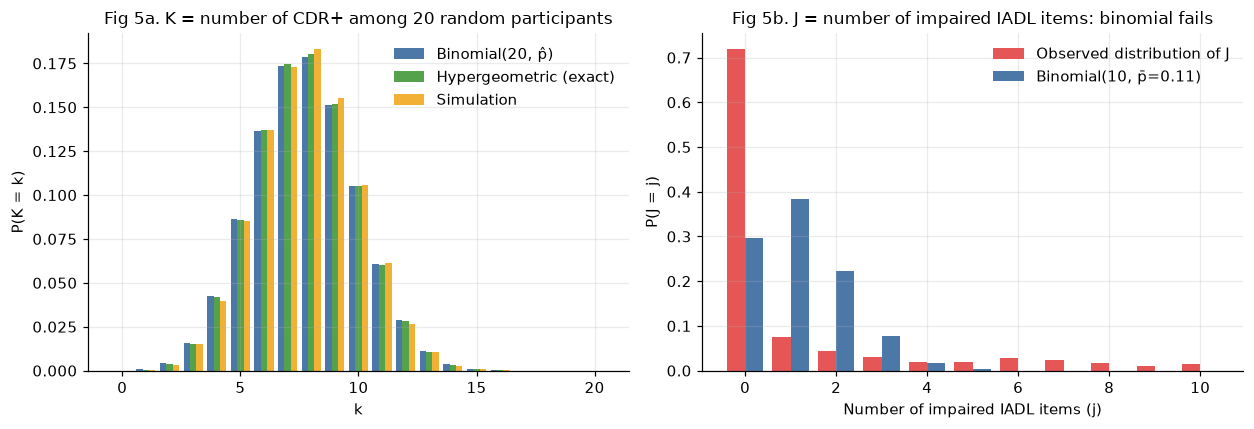

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))

xpos = np.arange(M_SAMPLE + 1)
ax[0].bar(xpos - 0.27, pmf_bin, 0.27, color=BLUE,  label="Binomial(20, p̂)")
ax[0].bar(xpos,        pmf_hyp, 0.27, color=GREEN, label="Hypergeometric (exact)")
ax[0].bar(xpos + 0.27, pmf_sim, 0.27, color=GOLD,  label="Simulation")
ax[0].set(title="Fig 5a. K = number of CDR+ among 20 random participants", xlabel="k", ylabel="P(K = k)")
ax[0].legend(frameon=False)

xp = np.arange(11)
ax[1].bar(xp - 0.2, obs_pmf.values, 0.4, color=RED,  label="Observed distribution of J")
ax[1].bar(xp + 0.2, bin_pmf,        0.4, color=BLUE, label=f"Binomial(10, p̄={p_bar:.2f})")
ax[1].set(title="Fig 5b. J = number of impaired IADL items: binomial fails",
          xlabel="Number of impaired IADL items (j)", ylabel="P(J = j)")
ax[1].legend(frameon=False)
save_fig("fig5_binomial")

<div dir="rtl">

**تفسیر.**

- شکل ۵الف: در سناریوی نمونه‌گیری تصادفی، سه منحنی تقریباً یکی‌اند. **دوجمله‌ای قابل قبول است.**
- شکل ۵ب: توزیع واقعی $J$ با دوجمله‌ای اختلاف دارد. احتمالاً جرم بیشتری روی صفر (بسیاری از افراد هیچ آیتمی مختل ندارند) و دُم سنگین‌تر در مقدارهای بزرگ (افراد دچار اختلال گسترده) می‌بینید — شکلی که با زنگوله‌ی دوجمله‌ای فرق دارد (شکل واقعی را از نمودار بخوانید). واریانس مشاهده‌شده چند برابر واریانس دوجمله‌ای است و میانگین هم‌بستگی بین آیتم‌ها مثبت است؛ **علت دقیق نقض فرض:** (۱) احتمال اختلال در آیتم‌ها یکسان نیست، (۲) مهم‌تر، آیتم‌ها به‌خاطر یک عامل مشترک (شدت بیماری) مستقل نیستند. هم‌پراکنشی مثبت مستقیماً واریانس مجموع را بزرگ می‌کند.

## ۶.۴ همگنی احتمال: $p$ در زیرگروه‌ها ثابت نیست
شرط «احتمال ثابت» حتی برای $K$ هم فقط وقتی درست است که نمونه از **کل** نمونه گرفته شود. اگر مثلاً فقط از افراد ۸۰ ساله و بالاتر بگیریم، $p$ عوض می‌شود:

</div>

In [20]:
rows = []
for band in df["AGE_band"].cat.categories:
    Bd = make_event(df["AGE_band"] == band, "NACCAGE")
    rows.append({"Age band": band, "n": n_of(Bd, CDR_pos), "P(CDR+ | band)": prob(CDR_pos, Bd)})
t64 = pd.DataFrame(rows).set_index("Age band")
display(t64)
print(f"احتمال کل: P(CDR+) = {prob(CDR_pos):.3f}")

,n,P(CDR+ | band)
Age band,,
<60,173,0.2948
60-69,512,0.3145
70-79,454,0.4758
>=80,98,0.5306


احتمال کل: P(CDR+) = 0.388


<div dir="rtl">

**تفسیر.** اگر $P(\text{CDR+}\mid\text{band})$ بین گروه‌های سنی تفاوت محسوس دارد، آنگاه $K$ شمارش‌شده در یک گروه سنی از $\text{Binomial}(20, p_{\text{کل}})$ پیروی **نمی‌کند**؛ باید با $p_{\text{band}}$ مدل شود. همین دلیل است که در کار با داده‌ی واقعی، «دوجمله‌ای» را همیشه همراه با ذکر **جامعه‌ای که از آن نمونه می‌گیریم** می‌آوریم.

**خلاصه‌ی بخش ۶**

| سناریو | دودویی | $m$ ثابت | $p$ ثابت | مستقل | نتیجه |
|---|---|---|---|---|---|
| $K$: تعداد CDR+ در ۲۰ نفرِ تصادفی از کل نمونه | ✔ | ✔ | تقریباً ✔ | تقریباً ✔ | دوجمله‌ای معقول |
| $K$ در ۲۰ نفرِ تصادفی از یک گروه سنیِ خاص | ✔ | ✔ | ✘ (با $p_{\text{band}}$ باید مدل شود) | تقریباً ✔ | با $p$ درست مدل می‌شود |
| $J$: تعداد آیتم‌های IADL مختل برای یک نفر | ✔ | ✔ | ✘ | ✘ | دوجمله‌ای مناسب نیست |

</div>

<div dir="rtl">

---
# ۷. متغیر پیوسته و توزیع نرمال (تسک ۶)

$X\sim N(\mu,\sigma^2)$ توزیعی متقارن و زنگوله‌ای است. «نرمال بودن» با یک عدد یا یک آزمون ثابت نمی‌شود؛ چند چیز را کنار هم می‌سنجیم:

1. **شکل:** هیستوگرام با منحنی نرمال برازش‌شده
2. **نمودار چندک–چندک (QQ):** اگر نقاط روی خط $y=x$ بنشینند، نرمال است؛ انحراف در دُم‌ها یعنی دُم سنگین یا سبک
3. **چولگی و کشیدگی:** چولگی ≈ ۰ و کشیدگی اضافه‌ی ≈ ۰ برای نرمال
4. **قاعده‌ی ۶۸–۹۵–۹۹٫۷:** سهم مشاهدات در $\pm1,2,3$ انحراف معیار با مقدار نظری مقایسه می‌شود
5. **کیفیت در دُم‌ها:** چون در مسئله‌ی ما «نازک» یعنی دُم پایین، اهمیت این است که نرمال دُم پایین را خوب پیش‌بینی کند.

متغیر بررسی‌شده: $X$ = `TH_ENTORHINAL`.

</div>

In [21]:
x = df["TH_ENTORHINAL"].dropna().to_numpy()
n_x = len(x)
mu, sd = x.mean(), x.std(ddof=1)
nd = NormalDist(mu, sd)
xs = pd.Series(x)
skew, ex_kurt = xs.skew(), xs.kurt()          # kurt() در pandas = کشیدگی اضافه (نرمال = 0)

print(f"n = {n_x} | میانگین = {mu:.3f} mm | SD = {sd:.3f} mm | میانه = {np.median(x):.3f}")
print(f"چولگی = {skew:.3f} | کشیدگی اضافه = {ex_kurt:.3f}   (نرمال: هر دو ≈ 0)")

cover = pd.DataFrame({
    "Empirical":   [np.mean(np.abs(x - mu) <= k * sd) for k in (1, 2, 3)],
    "Normal model": [nd.cdf(mu + k * sd) - nd.cdf(mu - k * sd) for k in (1, 2, 3)],
}, index=["within ±1 SD", "within ±2 SD", "within ±3 SD"])
cover["difference"] = cover["Empirical"] - cover["Normal model"]
print("\nقاعده‌ی تجربی:"); display(cover)

tails = pd.DataFrame({
    "Empirical": [np.mean(x < mu - sd), np.mean(x < mu - 2 * sd), np.mean(x > mu + sd), np.mean(x > mu + 2 * sd)],
    "Normal model": [nd.cdf(mu - sd), nd.cdf(mu - 2 * sd), 1 - nd.cdf(mu + sd), 1 - nd.cdf(mu + 2 * sd)],
}, index=["P(X < μ−σ)", "P(X < μ−2σ)", "P(X > μ+σ)", "P(X > μ+2σ)"])
tails["ratio emp/model"] = tails["Empirical"] / tails["Normal model"]
print("\nاحتمال دُم‌ها:"); display(tails)

n = 1224 | میانگین = 3.025 mm | SD = 0.337 mm | میانه = 3.060
چولگی = -0.511 | کشیدگی اضافه = 0.372   (نرمال: هر دو ≈ 0)

قاعده‌ی تجربی:


,Empirical,Normal model,difference
within ±1 SD,0.6879,0.6827,0.0052
within ±2 SD,0.9551,0.9545,0.0006
within ±3 SD,0.9951,0.9973,-0.0022



احتمال دُم‌ها:


,Empirical,Normal model,ratio emp/model
P(X < μ−σ),0.1618,0.1587,1.0196
P(X < μ−2σ),0.0368,0.0228,1.6160
P(X > μ+σ),0.1503,0.1587,0.9475
P(X > μ+2σ),0.0082,0.0228,0.3591


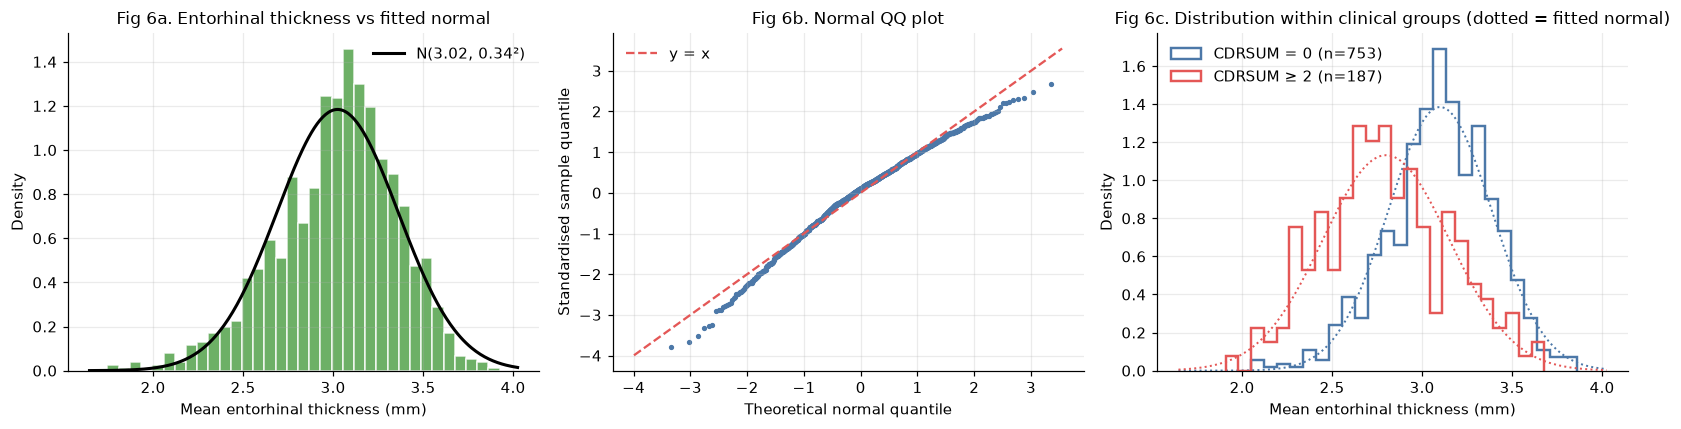

,n,mean,SD,skewness,excess kurtosis
CDR group,,,,,
0,753,3.0998,0.2881,-0.3931,0.3818
0.5-1.5,284,2.9736,0.3707,-0.6050,0.6504
2-4.5,139,2.8316,0.3516,0.1755,-0.3888
>=5,48,2.7080,0.3422,0.0197,-0.4762


In [22]:
std_nd = NormalDist()                                       # N(0,1) برای محور نظری QQ
sorted_x = np.sort(x)
theo_q = np.array([std_nd.inv_cdf((i - 0.5) / n_x) for i in range(1, n_x + 1)])
z_sorted = (sorted_x - mu) / sd

g0 = df.loc[df["CDRSUM"] == 0,  "TH_ENTORHINAL"].dropna().to_numpy()
g2 = df.loc[df["CDRSUM"] >= 2,  "TH_ENTORHINAL"].dropna().to_numpy()
grid = np.linspace(x.min() - 0.1, x.max() + 0.1, 300)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(x, bins=35, density=True, color=GREEN, edgecolor="white", alpha=0.85)
ax[0].plot(grid, [nd.pdf(v) for v in grid], color="black", lw=2, label=f"N({mu:.2f}, {sd:.2f}²)")
ax[0].set(title="Fig 6a. Entorhinal thickness vs fitted normal", xlabel="Mean entorhinal thickness (mm)", ylabel="Density")
ax[0].legend(frameon=False)

ax[1].scatter(theo_q, z_sorted, s=6, color=BLUE)
lim = [min(theo_q.min(), z_sorted.min()) - 0.2, max(theo_q.max(), z_sorted.max()) + 0.2]
ax[1].plot(lim, lim, color=RED, ls="--", label="y = x")
ax[1].set(title="Fig 6b. Normal QQ plot", xlabel="Theoretical normal quantile", ylabel="Standardised sample quantile")
ax[1].legend(frameon=False)

for arr, col, lab in [(g0, BLUE, "CDRSUM = 0"), (g2, RED, "CDRSUM ≥ 2")]:
    ax[2].hist(arr, bins=25, density=True, histtype="step", color=col, lw=1.6, label=f"{lab} (n={len(arr)})")
    nd_g = NormalDist(arr.mean(), arr.std(ddof=1))
    ax[2].plot(grid, [nd_g.pdf(v) for v in grid], color=col, ls=":", lw=1.3)
ax[2].set(title="Fig 6c. Distribution within clinical groups (dotted = fitted normal)",
          xlabel="Mean entorhinal thickness (mm)", ylabel="Density")
ax[2].legend(frameon=False)
save_fig("fig6_normality_entorhinal")

grp_rows = []
for g in CDR_LABELS:
    arr = df.loc[df["CDR_group"] == g, "TH_ENTORHINAL"].dropna()
    grp_rows.append({"CDR group": g, "n": len(arr), "mean": arr.mean(), "SD": arr.std(ddof=1),
                     "skewness": arr.skew(), "excess kurtosis": arr.kurt()})
display(pd.DataFrame(grp_rows).set_index("CDR group"))

<div dir="rtl">

**تفسیر.** (الگوی مورد انتظار؛ اعداد را از خروجی بخوانید.)

- هیستوگرام شکل زنگوله‌ای دارد ولی ممکن است دُم چپ (آتروفی) اندکی بلندتر باشد: چولگی منفی. در QQ plot این به‌صورت **انحراف نقاط پایین به زیر خط** دیده می‌شود.
- اگر قاعده‌ی ۶۸–۹۵–۹۹٫۷ تقریباً برقرار باشد (اختلاف چند درصد) و دُم‌ها تقریباً نظری باشند، **تقریب نرمال برای کل نمونه قابل قبول** است؛ اگر نسبت `emp/model` در دُم پایین از ۱ به‌مراتب بزرگ‌تر باشد، یعنی نرمال، افراد با ضخامت خیلی کم را **کم‌شمار** تخمین می‌زند.
- **چرا انحراف؟ مخلوط بودن:** نمونه ترکیبی از زیرگروه‌های بالینی با میانگین‌های متفاوت است (شکل ۶ج: گروه CDR≥2 به چپ منتقل شده). مخلوط چند توزیع نرمال با میانگین‌های متفاوت **نرمال نیست** حتی اگر هر زیرگروه نرمال باشد؛ دُم پایین را مخلوط می‌سازد. اگر درون هر گروه چولگی نزدیک‌تر به صفر و دُم‌ها نزدیک‌تر به نظری باشد، این توضیح تأیید می‌شود.
- **نتیجه‌ی مهم برای فاز بعد:** نرمال‌بودنِ *کل* $X$ شرط لازم بسیاری از روش‌ها نیست؛ آنچه معمولاً مهم است رفتار *باقیمانده‌ها* یا توزیع *درون گروه*‌هاست. پس همین‌جا «گزارش یک آزمون نرمال» کافی نیست؛ شکل و منشأ انحراف را هم توضیح دادیم.

## ۷.۱ مثال‌های نقض: `CDRSUM` و `MOCATOTS`
برای مقایسه، دو متغیر دیگر را هم با همان ابزار می‌سنجیم. `CDRSUM` گسسته و پُرصفر است؛ `MOCATOTS` سقف ۳۰ دارد و چوله به چپ است (فاز ۱). مدل نرمال برای هر دو **ناسازگار** است — حتی می‌شود نشان داد به مقدارهای **غیرممکن** احتمال مثبت می‌دهد.

</div>

,CDRSUM,MOCATOTS
n,"1,237.0000",984.0000
mean,0.8222,24.0285
SD,1.7230,4.7393
skewness,3.4712,-1.6436
excess kurtosis,15.6449,3.5547
% at minimum,61.1964,0.1016
% at maximum,0.0808,4.7764
model P(X < 0) (impossible),0.3166,NaN
model P(X > 30) (impossible),NaN,0.1038


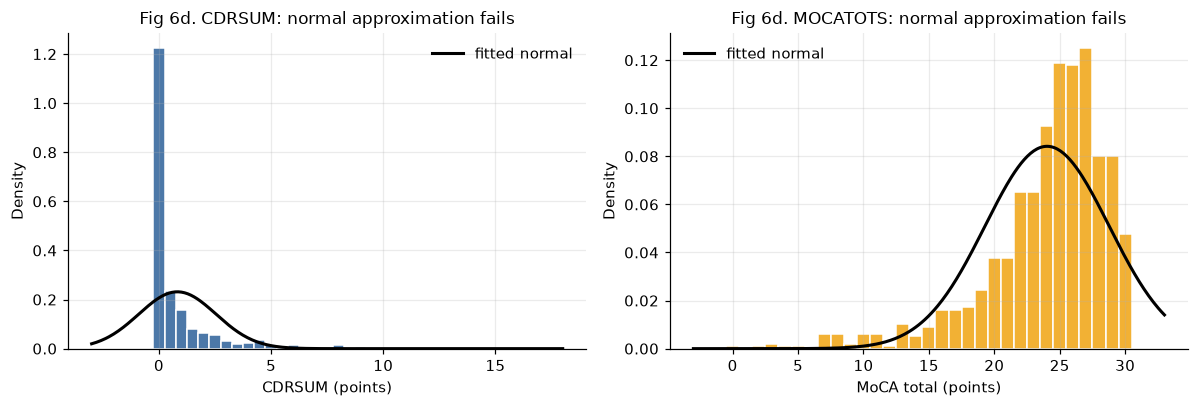

In [23]:
def normal_fit_report(name, s, lower=None, upper=None):
    s = s.dropna(); m, sdv = s.mean(), s.std(ddof=1); nd_ = NormalDist(m, sdv)
    out = {"n": len(s), "mean": m, "SD": sdv, "skewness": s.skew(), "excess kurtosis": s.kurt(),
           "% at minimum": 100 * (s == s.min()).mean(), "% at maximum": 100 * (s == s.max()).mean()}
    if lower is not None:
        out[f"model P(X < {lower}) (impossible)"] = nd_.cdf(lower)
    if upper is not None:
        out[f"model P(X > {upper}) (impossible)"] = 1 - nd_.cdf(upper)
    return pd.Series(out, name=name)

rep = pd.concat([normal_fit_report("CDRSUM", df["CDRSUM"], lower=0),
                 normal_fit_report("MOCATOTS", df["MOCATOTS"], upper=30)], axis=1)
display(rep)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
specs = [(ax[0], "CDRSUM", "CDRSUM (points)", BLUE, np.arange(-0.25, df["CDRSUM"].max() + 0.75, 0.5)),
         (ax[1], "MOCATOTS", "MoCA total (points)", GOLD, np.arange(-0.5, 31.5, 1))]
for axis, col, label, color, bins in specs:
    s = df[col].dropna()
    axis.hist(s, bins=bins, density=True, color=color, edgecolor="white")
    grid_ = np.linspace(s.min() - 3, s.max() + 3, 300)
    nd_ = NormalDist(s.mean(), s.std(ddof=1))
    axis.plot(grid_, [nd_.pdf(v) for v in grid_], color="black", lw=2, label="fitted normal")
    axis.set(title=f"Fig 6d. {col}: normal approximation fails", xlabel=label, ylabel="Density")
    axis.legend(frameon=False)
save_fig("fig6d_normal_fails_cdr_moca")

<div dir="rtl">

**تفسیر.** برای `CDRSUM` توزیع نرمال برازش‌شده مقدار مثبتی به $C<0$ می‌دهد که **غیرممکن** است؛ همچنین بیش از نیمی از جرم واقعی روی یک نقطه (صفر) است که یک چگالی پیوسته نمی‌تواند نشان دهد. برای `MOCATOTS` نیز نرمال به نمره‌های بالای ۳۰ جرم می‌دهد و نمودار واقعی انباشت در نزدیکی سقف دارد. **نتیجه:** نرمال برای `CDRSUM` و `MOCATOTS` مناسب نیست؛ به همین دلیل در تحلیل‌های بعدی برای `CDRSUM` از خلاصه‌های مقاوم (میانه، گروه‌بندی) و روش‌های بدون فرض نرمال (مثل همبستگی رتبه‌ای) استفاده می‌کنیم.

## ۷.۲ محاسبه با مدل نرمال و مقایسه با واقعیت
اگر $X\sim N(\mu,\sigma^2)$ باشد:

$$P(X\le t)=\Phi\!\left(\frac{t-\mu}{\sigma}\right),\qquad z=\frac{t-\mu}{\sigma}$$

دو کاربرد:

- **کالیبراسیون:** مدل نرمال کلِ نمونه، احتمال $P(X\le q_{25})$ را چقدر پیش‌بینی می‌کند؟ (واقعیت ۰٫۲۵ است.)
- **مدل درون‌گروهی:** با نرمال هر گروه بالینی، $P(\text{Thin}\mid\text{گروه})$ را پیش‌بینی می‌کنیم و با فراوانی تجربی مقایسه می‌کنیم. اگر نرمال خوب باشد، دو عدد نزدیک‌اند.
- **زمینه‌دار بودن «غیرعادی»:** یک مقدار ثابت (مثلاً ۲٫۲ میلی‌متر) نسبت به کل نمونه و نسبت به گروه CDR=0 جایگاه (z) متفاوتی دارد.

</div>

In [24]:
print(f"کالیبراسیون روی کل نمونه: مدل نرمال P(X ≤ {Q25:.3f}) = {nd.cdf(Q25):.3f} (واقعیت: {np.mean(x <= Q25):.3f})\n")

rows = []
for lab, arr in [("CDRSUM = 0", g0), ("CDRSUM >= 2", g2)]:
    ndg = NormalDist(arr.mean(), arr.std(ddof=1))
    rows.append({"Group": lab, "n": len(arr), "mean": arr.mean(), "SD": arr.std(ddof=1),
                 "Normal-model P(Thin | group)": ndg.cdf(Q25),
                 "Empirical P(Thin | group)": np.mean(arr <= Q25)})
t72 = pd.DataFrame(rows).set_index("Group")
t72["difference"] = t72["Normal-model P(Thin | group)"] - t72["Empirical P(Thin | group)"]
display(t72)

t_val = 2.2
nd0 = NormalDist(g0.mean(), g0.std(ddof=1))
print(f"\nمثال: ضخامت {t_val} mm")
print(f"  نسبت به کل نمونه:       z = {(t_val - mu) / sd:+.2f} → صدک مدل نرمال = {100 * nd.cdf(t_val):.1f}% | صدک تجربی = {100 * np.mean(x <= t_val):.1f}%")
print(f"  نسبت به گروه CDRSUM=0:  z = {(t_val - nd0.mean) / nd0.stdev:+.2f} → صدک مدل نرمال = {100 * nd0.cdf(t_val):.1f}% | صدک تجربی = {100 * np.mean(g0 <= t_val):.1f}%")

کالیبراسیون روی کل نمونه: مدل نرمال P(X ≤ 2.812) = 0.264 (واقعیت: 0.250)



,n,mean,SD,Normal-model P(Thin | group),Empirical P(Thin | group),difference
Group,,,,,,
CDRSUM = 0,753,3.0998,0.2881,0.1587,0.1633,-0.0046
CDRSUM >= 2,187,2.7999,0.3525,0.5134,0.5561,-0.0427



مثال: ضخامت 2.2 mm
  نسبت به کل نمونه:       z = -2.45 → صدک مدل نرمال = 0.7% | صدک تجربی = 1.7%
  نسبت به گروه CDRSUM=0:  z = -3.12 → صدک مدل نرمال = 0.1% | صدک تجربی = 0.5%


<div dir="rtl">

**تفسیر.** اگر اختلاف بین مدل و واقعیت در `t72` کوچک باشد (مثلاً کمتر از ۲–۳ درصد)، نرمال درون‌گروهی برای محاسبه‌ی احتمال «Thin» کاملاً قابل استفاده است؛ اگر بزرگ باشد، چولگی/دُم سنگین آن را خراب می‌کند. مثالِ ۲٫۲ میلی‌متر نکته‌ی دیگری را نشان می‌دهد: **«غیرعادی» بودن مفهومی نسبی است** — همان مقدار نسبت به نمونه‌ی کل کمی غیرعادی است ولی نسبت به افراد سالم (CDRSUM=0) بسیار غیرعادی‌تر. این دقیقاً همان چیزی است که شرط‌گذاری در احتمال شرطی می‌گوید.

</div>

<div dir="rtl">

---
# ۸. امید ریاضی و واریانس (تسک ۷ و J.2)

برای متغیر تصادفی گسسته $C$ با تابع جرم $p(c)$:

$$E[C]=\sum_c c\,p(c),\qquad \mathrm{Var}(C)=E[C^2]-\big(E[C]\big)^2=\sum_c (c-E[C])^2\,p(c)$$

- **امید ریاضی** = «مرکز ثقل» توزیع؛ میانگینِ بلندمدتِ مقدار برای یک شرکت‌کننده‌ی تصادفی.
- **واریانس** = میانگینِ مربع فاصله از امید؛ واحدش مربع واحد متغیر است. **انحراف معیار** $\sigma=\sqrt{\mathrm{Var}}$ همان واحد خودِ متغیر را دارد.
- برای **توزیع تجربی** (هر نفر وزن $1/n$) امید همان میانگین نمونه و واریانس، واریانس با مخرج $n$ است. (واریانس نمونه‌ایِ استاندارد با مخرج $n-1$ برای برآورد جامعه به کار می‌رود؛ هر دو را گزارش می‌کنیم و فرقشان در $n\approx1200$ ناچیز است.)

## ۸.۱ امید و واریانس `CDRSUM` از روی تابع جرم تجربی

</div>

In [25]:
c = df["CDRSUM"].dropna()
pmf = c.value_counts(normalize=True).sort_index()
cnts = c.value_counts().sort_index()
vals, probs = pmf.index.to_numpy(float), pmf.to_numpy()

E_c  = float((vals * probs).sum())
E_c2 = float((vals**2 * probs).sum())
V_c  = E_c2 - E_c**2

assert np.isclose(E_c, c.mean()) and np.isclose(V_c, c.var(ddof=0))      # با محاسبه‌ی مستقیم یکی است

tab_pmf = pd.DataFrame({"count": cnts, "p(c)": pmf, "cumulative": pmf.cumsum(), "c·p(c)": vals * probs})
tab_pmf.index = [f"{v:g}" for v in tab_pmf.index]; tab_pmf.index.name = "CDRSUM = c"
display(tab_pmf)

print(f"E[C]            = {E_c:.3f} امتیاز")
print(f"E[C²]           = {E_c2:.3f}")
print(f"Var(C) = E[C²]−E[C]² = {V_c:.3f} امتیاز²   (واریانس نمونه‌ای با n−1: {c.var(ddof=1):.3f})")
print(f"SD(C)           = {math.sqrt(V_c):.3f} امتیاز")
print(f"میانه = {c.median():.1f} | مد = {c.mode().iloc[0]:.1f} | P(C = 0) = {pmf.get(0.0, 0):.3f}")
reg_other("E[CDRSUM]", E_c, "points")
reg_other("Var(CDRSUM) [n]", V_c, "points²")

,count,p(c),cumulative,c·p(c)
CDRSUM = c,,,,
0,757,0.6120,0.6120,0.0000
0.5,144,0.1164,0.7284,0.0582
1,97,0.0784,0.8068,0.0784
1.5,50,0.0404,0.8472,0.0606
2,39,0.0315,0.8787,0.0631
2.5,35,0.0283,0.9070,0.0707
3,20,0.0162,0.9232,0.0485
3.5,12,0.0097,0.9329,0.0340
4,14,0.0113,0.9442,0.0453


E[C]            = 0.822 امتیاز
E[C²]           = 3.642
Var(C) = E[C²]−E[C]² = 2.966 امتیاز²   (واریانس نمونه‌ای با n−1: 2.969)
SD(C)           = 1.722 امتیاز
میانه = 0.0 | مد = 0.0 | P(C = 0) = 0.612


<div dir="rtl">

**تفسیر در متن مسئله.**

- $E[C]\approx0.82$ یعنی اگر یک شرکت‌کننده را تصادفی برداریم، «انتظار» نمره‌ی CDRSUM او کمتر از یک امتیاز است. ولی **هیچ‌کس این مقدار را ندارد**: بیش از نیمی از افراد دقیقاً صفر هستند و میانه ۰ است.
- مثبت‌تر بودن امید از میانه یعنی **دنباله‌ی بلند به راست**: تعداد کمی از افراد نمره‌های بالا دارند و میانگین را بالا می‌کشند.
- انحراف معیار حدود دو برابر امید است. یعنی قاعده‌ی «میانگین ± SD» برای این متغیر بی‌معنی می‌شود (پایین‌ترین مقدار ممکن، صفر است و $E[C]-\sigma<0$). **امید و واریانس برای متغیر پُرصفر شاخصِ خوبی از «حالت معمول» نیستند**؛ باید همراه میانه و سهم صفرها گزارش شوند.

## ۸.۲ توزیع یک نمره‌ی شناختی و یک متغیر MRI (J.2)
برای دو متغیر از UDS و یک متغیر از MRI، شکل توزیع، میانگین، واریانس و نقاط دورافتاده را گزارش می‌کنیم:

- `CDRSUM` — نمره‌ی بالینی (متغیر اصلی پروژه)
- `MOCATOTS` — نمره‌ی شناختی (آزمون MoCA، ۰ تا ۳۰)؛ فاز ۱ نشان داد ۲۰٫۵٪ آن گم است و گمشدگی‌اش به تشخیص وابسته است، پس تفسیرش باید با احتیاط باشد.
- `TH_ENTORHINAL` — متغیر MRI (میلی‌متر)

**نقاط دورافتاده** با دو معیار: قاعده‌ی تاکی ($1.5\times$IQR خارج از چارک‌ها) و $|z|>3$. دورافتاده‌بودن آماری با «خطا» یکی نیست؛ برای افرادِ شدیداً بیمار مقدارهای بالای `CDRSUM` یا پایین `MOCATOTS` **واقعی و معنی‌دارند** (فاز ۱) و حذف نمی‌شوند.

</div>

In [26]:
def shape_label(s):
    sk = s.skew()
    zero_share = (s == s.min()).mean()
    if zero_share > 0.4:
        return f"zero-inflated ({100 * zero_share:.0f}% at minimum), right-skewed" if sk > 0 else "mass at minimum"
    if abs(sk) < 0.5:
        return "roughly symmetric"
    return "right-skewed" if sk > 0 else "left-skewed"

def describe_rv(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std(ddof=1)
    return {"n": len(s), "mean": s.mean(), "variance (n-1)": s.var(ddof=1), "SD": s.std(ddof=1),
            "median": s.median(), "Q1": q1, "Q3": q3, "skewness": s.skew(), "excess kurtosis": s.kurt(),
            "shape": shape_label(s),
            "Tukey low": int((s < lo).sum()), "Tukey high": int((s > hi).sum()), "|z|>3": int((z.abs() > 3).sum()),
            "min": s.min(), "max": s.max()}

t82 = pd.DataFrame({"CDRSUM (UDS, clinical)": describe_rv(df["CDRSUM"]),
                    "MOCATOTS (UDS, cognitive)": describe_rv(df["MOCATOTS"]),
                    "TH_ENTORHINAL (MRI, mm)": describe_rv(df["TH_ENTORHINAL"])})
display(t82)

,"CDRSUM (UDS, clinical)","MOCATOTS (UDS, cognitive)","TH_ENTORHINAL (MRI, mm)"
n,1237,984,1224
mean,0.8222,24.0285,3.0247
variance (n-1),2.9687,22.4610,0.1135
SD,1.7230,4.7393,0.3369
median,0.0000,25.0000,3.0597
Q1,0.0000,22.0000,2.8117
Q3,1.0000,27.0000,3.2557
skewness,3.4712,-1.6436,-0.5114
excess kurtosis,15.6449,3.5547,0.3720
shape,"zero-inflated (61% at minimum), right-skewed",left-skewed,left-skewed


<div dir="rtl">

**تفسیر (شکل، میانگین، واریانس، دورافتاده‌ها).**

- **`CDRSUM`:** پُرصفر و چوله به راست؛ میانگین بالاتر از میانه؛ قاعده‌ی تاکی به‌خاطر اینکه $Q_1=0$ و $Q_3$ کوچک است همه‌ی نمره‌های نسبتاً بالا را «دورافتاده» می‌شمرد — یعنی اینجا این معیار گمراه‌کننده است، نه نشانه‌ی خطا.
- **`MOCATOTS`:** چوله به چپ با تجمع نزدیک سقف؛ دورافتاده‌ها در سمت پایین (افراد بیمارتر)؛ ۲۰٫۵٪ گم‌شده است، بنابراین میانگین و واریانس فقط درباره‌ی ۷۹٪ دارای MoCA صدق می‌کند و ممکن است سالم‌ها را کم‌نمایش دهد.
- **`TH_ENTORHINAL`:** شکل (چولگی و کشیدگی) و تعداد دورافتاده‌ها را از جدول بخوانید؛ در فاز ۱ توزیع تقریباً متقارن بود و تعداد دورافتاده‌ها اندک. مقدارهای خیلی کم با آتروفی واقعی سازگارند و حذف نشدند.

## ۸.۳ قانون امید کل و قانون واریانس کل (پیوند با سؤال پروژه)
گروه‌های CDR یک **افراز** از نمونه‌اند. برای هر گروه $G$:

$$E[X]=\sum_G P(G)\,E[X\mid G]\qquad\text{(قانون امید کل)}$$

$$\mathrm{Var}(X)=\underbrace{\sum_G P(G)\,\mathrm{Var}(X\mid G)}_{\text{درون‌گروهی}}+\underbrace{\sum_G P(G)\,\big(E[X\mid G]-E[X]\big)^2}_{\text{بین‌گروهی}}\qquad\text{(قانون واریانس کل)}$$

سهم بین‌گروهی از کل واریانس، یعنی **«چه کسری از تغییرات ضخامت را صرفاً دانستنِ گروه CDR توضیح می‌دهد»**:
$\eta^2=\dfrac{\text{بین‌گروهی}}{\mathrm{Var}(X)}$. این هم‌خانواده‌ی ایده‌ی $R^2$ است ولی اینجا فقط یک اتحاد احتمالی روی داده است، نه آزمون.

</div>

,n,P(G),E[X | G],Var(X | G),SD(X | G)
CDR_group,,,,,
0,753,0.6152,3.0998,0.0829,0.2879
0.5-1.5,284,0.2320,2.9736,0.1369,0.3700
2-4.5,139,0.1136,2.8316,0.1227,0.3503
>=5,48,0.0392,2.7080,0.1147,0.3386


E[X] = Σ P(G)·E[X|G] = 3.0247  (میانگین مستقیم: 3.0247) ✔
Var(X) = 0.1134 = درون‌گروهی 0.1012 + بین‌گروهی 0.0122 ✔
η² = بین‌گروهی / کل = 0.108  → 10.8% از تغییرات ضخامت با دانستن گروه CDR توضیح داده می‌شود


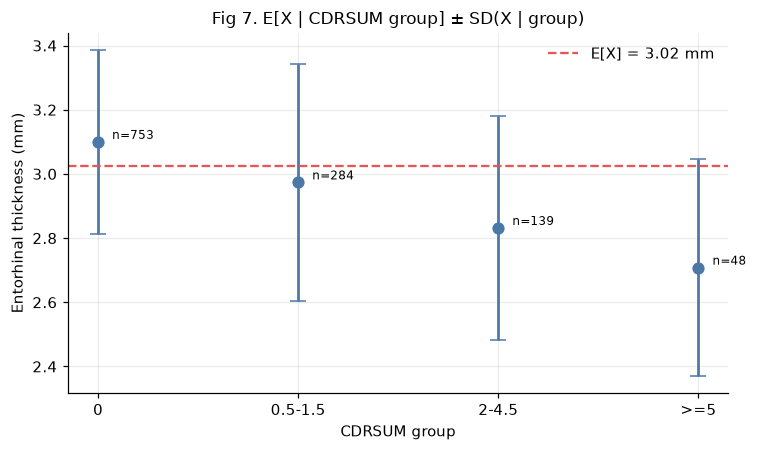

In [27]:
d = df[["TH_ENTORHINAL", "CDR_group"]].dropna()
grp = d.groupby("CDR_group", observed=True)["TH_ENTORHINAL"]
w, m_g, v_g = grp.size() / len(d), grp.mean(), grp.var(ddof=0)

t83 = pd.DataFrame({"n": grp.size(), "P(G)": w, "E[X | G]": m_g, "Var(X | G)": v_g, "SD(X | G)": np.sqrt(v_g)})
display(t83)

E_X = float((w * m_g).sum())
within = float((w * v_g).sum())
between = float((w * (m_g - E_X) ** 2).sum())
total = float(d["TH_ENTORHINAL"].var(ddof=0))

assert np.isclose(E_X, d["TH_ENTORHINAL"].mean()), "قانون امید کل برقرار نیست"
assert np.isclose(within + between, total),         "قانون واریانس کل برقرار نیست"

print(f"E[X] = Σ P(G)·E[X|G] = {E_X:.4f}  (میانگین مستقیم: {d['TH_ENTORHINAL'].mean():.4f}) ✔")
print(f"Var(X) = {total:.4f} = درون‌گروهی {within:.4f} + بین‌گروهی {between:.4f} ✔")
print(f"η² = بین‌گروهی / کل = {between / total:.3f}  → {100 * between / total:.1f}% از تغییرات ضخامت با دانستن گروه CDR توضیح داده می‌شود")
reg_other("eta² = Var(E[X|G]) / Var(X)  (CDR group, entorhinal)", between / total, "fraction")

fig, ax = plt.subplots(figsize=(7, 4.2))
xpos = np.arange(len(t83))
ax.errorbar(xpos, t83["E[X | G]"], yerr=t83["SD(X | G)"], fmt="o", color=BLUE, capsize=5, lw=1.8, ms=7)
ax.axhline(E_X, color=RED, ls="--", label=f"E[X] = {E_X:.2f} mm")
for i, (n_, mm) in enumerate(zip(t83["n"], t83["E[X | G]"])):
    ax.text(i + 0.07, mm, f"n={n_}", fontsize=8, va="bottom")
ax.set_xticks(xpos, t83.index)
ax.set(title="Fig 7. E[X | CDRSUM group] ± SD(X | group)", xlabel="CDRSUM group", ylabel="Entorhinal thickness (mm)")
ax.legend(frameon=False)
save_fig("fig7_conditional_expectation")

<div dir="rtl">

**تفسیر.** اتحادها دقیق برقرار شدند (کنترل با `assert`). نکته‌ی مفهومی: **امیدِ شرطی** $E[X\mid G]$ همان «میانگین ضخامت در هر گروه CDR» است — یعنی همان چیزی که در فاز ۱ با میانه‌ها وصف کردیم، حالا در قالب احتمال. اگر $\eta^2$ کوچک تا متوسط باشد (مثلاً ۱۰٪)، یعنی گروه CDR بخشی از تغییرات ضخامت را توضیح می‌دهد ولی **بیشترِ تغییرات** از مسیرهای دیگر می‌آید (تفاوت‌های فردی، سن، ...)؛ همین سازگار با هم‌پوشانی بالای چارک‌ها در فاز ۱ است. رابطه‌ای که «روند است نه جدایی کامل».

</div>

<div dir="rtl">

---
# ۹. دو متغیر تصادفی و کوواریانس (تسک ۸ و J.4)

برای دو متغیر $X$ و $Y$:

$$\mathrm{Cov}(X,Y)=E\big[(X-E[X])(Y-E[Y])\big]=E[XY]-E[X]\,E[Y]$$

- **علامت** جهت رابطه را می‌گوید: مثبت = با بالا رفتن یکی، دیگری معمولاً بالا می‌رود؛ منفی = برعکس؛ نزدیک صفر = رابطه‌ی خطی ضعیف.
- **اندازه** به **واحدها** وابسته است (واحد: واحد $X$ × واحد $Y$)؛ پس اندازه‌ی کوواریانس به‌تنهایی «قدرت» رابطه را نمی‌گوید. با استانداردسازی **ضریب همبستگی** $r=\dfrac{\mathrm{Cov}(X,Y)}{\sigma_X\sigma_Y}\in[-1,1]$ بی‌بُعد می‌شود.
- چون `CDRSUM` پُرصفر و چوله است، **همبستگی رتبه‌ای اسپیرمن** $\rho$ (همبستگی روی رتبه‌ها) را هم گزارش می‌کنیم که به چولگی و دورافتاده حساس نیست.
- **این‌ها فقط توصیف همراهی‌اند.** آزمون رسمی و استنباط (فاصله‌ی اطمینان، p-value) در فاز ۴ می‌آید و از رابطه نتیجه‌ی علّی نمی‌گیریم: از «CDRSUM بالاتر ⟷ ضخامت کمتر» نمی‌توان نتیجه گرفت که یکی دیگری را کم می‌کند.

</div>

In [29]:
def cov_report(xn, yn):
    d = df[[xn, yn]].dropna()
    x_, y_ = d[xn].to_numpy(float), d[yn].to_numpy(float)
    n_ = len(d)
    cov = np.cov(x_, y_, ddof=1)[0, 1]
    # اتحاد Cov = E[XY] − E[X]E[Y] (با تصحیح n/(n−1) برای واریانس نمونه‌ای)
    assert np.isclose(cov, (np.mean(x_ * y_) - x_.mean() * y_.mean()) * n_ / (n_ - 1))
    r = np.corrcoef(x_, y_)[0, 1]
    rho_ = d[xn].rank().corr(d[yn].rank())
    sign = "negative" if cov < 0 else "positive"
    return {"n": n_, "covariance": cov, "Pearson r": r, "Spearman ρ": rho_, "direction": sign}

pairs9 = [("CDRSUM", "TH_ENTORHINAL"), ("CDRSUM", "TH_PARAHIPPOCAMPAL"), ("CDRSUM", "TH_MIDDLETEMPORAL"),
          ("MOCATOTS", "TH_ENTORHINAL"), ("NACCAGE", "TH_ENTORHINAL"), ("NACCAGE", "CDRSUM"), ("EDUC", "TH_ENTORHINAL")]
t9 = pd.DataFrame({f"{a_} , {b_}": cov_report(a_, b_) for a_, b_ in pairs9}).T
t9["n"] = t9["n"].astype(int)
display(t9)

main = cov_report("CDRSUM", "TH_ENTORHINAL")
reg_other("Cov(CDRSUM, TH_ENTORHINAL)", main["covariance"], "points·mm")
reg_other("Pearson r(CDRSUM, TH_ENTORHINAL)", main["Pearson r"], "")
reg_other("Spearman rho(CDRSUM, TH_ENTORHINAL)", main["Spearman ρ"], "")
print(f"\nپروژه‌ی اصلی: Cov(CDRSUM, ضخامت انتورینال) = {main['covariance']:.4f} (امتیاز × میلی‌متر) → جهت {main['direction']}")
print(f"r = {main['Pearson r']:.3f} | ρ (رتبه‌ای) = {main['Spearman ρ']:.3f} | n = {main['n']}")

,n,covariance,Pearson r,Spearman ρ,direction
"CDRSUM , TH_ENTORHINAL",1224,-0.1808,-0.3100,-0.3051,negative
"CDRSUM , TH_PARAHIPPOCAMPAL",1225,-0.0962,-0.2332,-0.2476,negative
"CDRSUM , TH_MIDDLETEMPORAL",1225,-0.0912,-0.3814,-0.3083,negative
"MOCATOTS , TH_ENTORHINAL",977,0.5529,0.3461,0.3230,positive
"NACCAGE , TH_ENTORHINAL",1224,-0.7689,-0.2837,-0.2774,negative
"NACCAGE , CDRSUM",1237,0.8097,0.0585,0.1715,positive
"EDUC , TH_ENTORHINAL",1222,0.0186,0.0203,0.0382,positive



پروژه‌ی اصلی: Cov(CDRSUM, ضخامت انتورینال) = -0.1808 (امتیاز × میلی‌متر) → جهت negative
r = -0.310 | ρ (رتبه‌ای) = -0.305 | n = 1224


<div dir="rtl">

### سه کنترل مفهومی روی کوواریانس

**۱) وابستگی به واحد.** اگر ضخامت را به میکرومتر بیان کنیم، کوواریانس ۱۰۰۰ برابر می‌شود ولی همبستگی تغییری نمی‌کند.

**۲) واریانس مجموع.** $\mathrm{Var}(X+Y)=\mathrm{Var}(X)+\mathrm{Var}(Y)+2\,\mathrm{Cov}(X,Y)$. در پروژه‌ی ما ضخامت انتورینال **میانگین** نیمکره‌ی چپ و راست است ($X=\tfrac{L+R}{2}$)؛ پس $\mathrm{Var}(X)=\tfrac14\big[\mathrm{Var}(L)+\mathrm{Var}(R)+2\mathrm{Cov}(L,R)\big]$. چون دو نیمکره قویاً هم‌بسته‌اند، میانگین‌گیری واریانس را به‌اندازه‌ی ساده‌ی «نصف شدن» کم نمی‌کند — همین تأییدی است بر اینکه نمی‌توان چپ و راست را دو مشاهده‌ی مستقل شمرد.

**۳) کوواریانس سن.** چون سن با هر دو متغیر هم‌بسته است (جدول بالا)، رابطه‌ی خامِ CDRSUM–ضخامت ممکن است بخشی از رابطه‌ی هر دو با سن باشد. برای اینکه ببینیم رابطه با سن «تعدیل» می‌شود یا نه، **رابطه‌ی باقیمانده** را می‌گیریم: هر دو متغیر را روی (سن، جنس، تحصیل) با کمترین مربعات خطی رگرس می‌کنیم و کوواریانس/همبستگی **باقیمانده‌ها** را می‌سنجیم (همبستگی جزئی). این هنوز توصیف است، نه استنباط.

</div>

In [30]:
# ---- ۱) وابستگی به واحد
d1 = df[["CDRSUM", "TH_ENTORHINAL"]].dropna()
cov_mm = np.cov(d1["CDRSUM"], d1["TH_ENTORHINAL"], ddof=1)[0, 1]
cov_um = np.cov(d1["CDRSUM"], d1["TH_ENTORHINAL"] * 1000, ddof=1)[0, 1]
r_mm = np.corrcoef(d1["CDRSUM"], d1["TH_ENTORHINAL"])[0, 1]
r_um = np.corrcoef(d1["CDRSUM"], d1["TH_ENTORHINAL"] * 1000)[0, 1]
print(f"۱) واحد: Cov با mm = {cov_mm:.4f} | با µm = {cov_um:.2f} (نسبت {cov_um / cov_mm:.0f}) | r با mm = {r_mm:.4f}، با µm = {r_um:.4f}")

# ---- ۲) Var(میانگین چپ و راست) = ¼[Var L + Var R + 2 Cov(L,R)]
lr = df[["LH_ENTORHINAL_AVGTH", "RH_ENTORHINAL_AVGTH"]].dropna()
vL, vR, cLR = lr.iloc[:, 0].var(ddof=1), lr.iloc[:, 1].var(ddof=1), np.cov(lr.iloc[:, 0], lr.iloc[:, 1], ddof=1)[0, 1]
var_mean_direct = ((lr.iloc[:, 0] + lr.iloc[:, 1]) / 2).var(ddof=1)
var_mean_formula = 0.25 * (vL + vR + 2 * cLR)
assert np.isclose(var_mean_direct, var_mean_formula)
print(f"۲) Var(L)={vL:.4f}, Var(R)={vR:.4f}, Cov(L,R)={cLR:.4f}, r(L,R)={cLR / math.sqrt(vL * vR):.3f}")
print(f"   Var((L+R)/2) مستقیم = {var_mean_direct:.4f} | از فرمول = {var_mean_formula:.4f} ✔")
print(f"   اگر L و R مستقل بودند: {0.25 * (vL + vR):.4f} (کمتر از واقعی؛ تفاوت از Cov(L,R) می‌آید)")

# ---- ۳) همبستگی جزئی (توصیفی): باقیمانده پس از حذف خطی سن، جنس، تحصیل
dd = df[["CDRSUM", "TH_ENTORHINAL", "NACCAGE", "SEX", "EDUC"]].dropna()
Xc = np.column_stack([np.ones(len(dd)), dd["NACCAGE"], (dd["SEX"] == 2).astype(float), dd["EDUC"]])

def residuals(y, X):
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    return y - X @ beta

rx = residuals(dd["CDRSUM"].to_numpy(float), Xc)
ry = residuals(dd["TH_ENTORHINAL"].to_numpy(float), Xc)
rxr = residuals(dd["CDRSUM"].rank().to_numpy(float), Xc)               # نسخه‌ی رتبه‌ای
ryr = residuals(dd["TH_ENTORHINAL"].rank().to_numpy(float), Xc)
partial = pd.DataFrame({"covariance": [np.cov(dd["CDRSUM"], dd["TH_ENTORHINAL"])[0, 1], np.cov(rx, ry)[0, 1]],
                        "Pearson r": [np.corrcoef(dd["CDRSUM"], dd["TH_ENTORHINAL"])[0, 1], np.corrcoef(rx, ry)[0, 1]],
                        "rank-based r": [dd["CDRSUM"].rank().corr(dd["TH_ENTORHINAL"].rank()), np.corrcoef(rxr, ryr)[0, 1]]},
                       index=["raw (no adjustment)", "after removing age, sex, education (linear)"])
print(f"\n۳) همبستگی جزئی (n = {len(dd)}):"); display(partial)
reg_other("Partial rank-corr(CDRSUM, entorhinal | age, sex, educ)", partial.iloc[1, 2], "")

۱) واحد: Cov با mm = -0.1808 | با µm = -180.77 (نسبت 1000) | r با mm = -0.3100، با µm = -0.3100
۲) Var(L)=0.1370, Var(R)=0.1391, Cov(L,R)=0.0890, r(L,R)=0.645
   Var((L+R)/2) مستقیم = 0.1135 | از فرمول = 0.1135 ✔
   اگر L و R مستقل بودند: 0.0690 (کمتر از واقعی؛ تفاوت از Cov(L,R) می‌آید)

۳) همبستگی جزئی (n = 1222):


,covariance,Pearson r,rank-based r
raw (no adjustment),-0.1798,-0.3088,-0.3032
"after removing age, sex, education (linear)",-0.1694,-0.3055,-0.2737


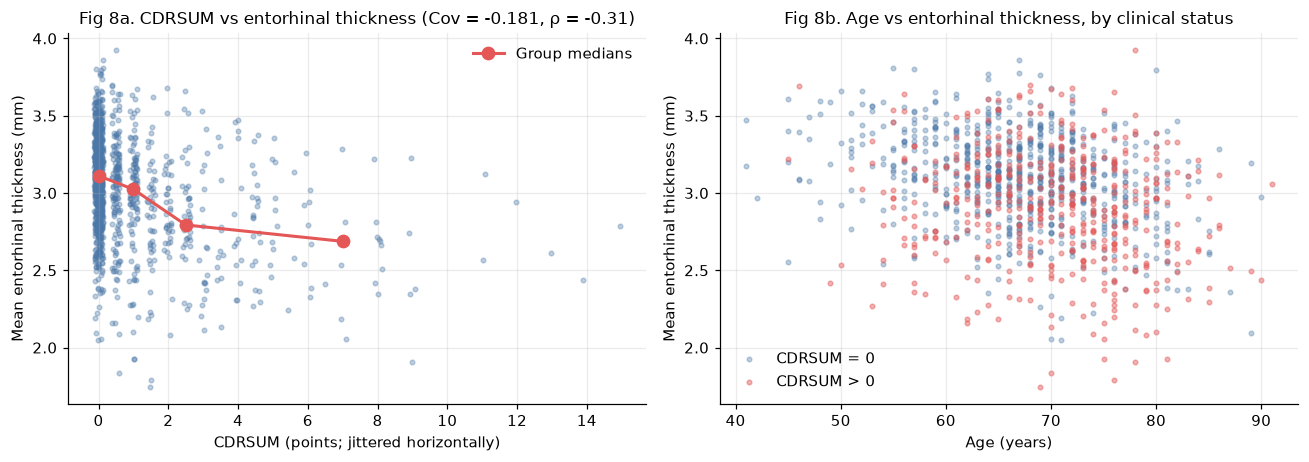

In [31]:
d = df[["CDRSUM", "TH_ENTORHINAL", "NACCAGE"]].dropna()
jit = RNG.uniform(-0.12, 0.12, len(d))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].scatter(d["CDRSUM"] + jit, d["TH_ENTORHINAL"], s=9, alpha=0.35, color=BLUE)
med = d.groupby(pd.cut(d["CDRSUM"], [-0.1, 0, 1.5, 4.5, np.inf], labels=CDR_LABELS), observed=True).agg(
    x=("CDRSUM", "median"), y=("TH_ENTORHINAL", "median"))
ax[0].plot(med["x"], med["y"], "o-", color=RED, lw=2, ms=8, label="Group medians")
ax[0].set(title=f"Fig 8a. CDRSUM vs entorhinal thickness (Cov = {main['covariance']:.3f}, ρ = {main['Spearman ρ']:.2f})",
          xlabel="CDRSUM (points; jittered horizontally)", ylabel="Mean entorhinal thickness (mm)")
ax[0].legend(frameon=False)

pos = d["CDRSUM"] > 0
ax[1].scatter(d.loc[~pos, "NACCAGE"], d.loc[~pos, "TH_ENTORHINAL"], s=9, alpha=0.35, color=BLUE, label="CDRSUM = 0")
ax[1].scatter(d.loc[pos, "NACCAGE"],  d.loc[pos, "TH_ENTORHINAL"],  s=9, alpha=0.45, color=RED,  label="CDRSUM > 0")
ax[1].set(title="Fig 8b. Age vs entorhinal thickness, by clinical status",
          xlabel="Age (years)", ylabel="Mean entorhinal thickness (mm)")
ax[1].legend(frameon=False)
save_fig("fig8_scatter_covariance")

<div dir="rtl">

**تفسیر.**

- **جهت:** کوواریانس منفی است: با بالا رفتن `CDRSUM` ضخامت انتورینال معمولاً کمتر می‌شود. ضریب رتبه‌ای حدود $-0.3$ (فاز ۱) رابطه‌ای **متوسط** است، نه قوی: ابر نقاط پهن است و مرکز هر گروه با گروه کناری هم‌پوشانی دارد.
- **چرا کوواریانس به‌تنهایی کافی نیست:** مقدارش به واحد وابسته است (کنترل ۱). برای مقایسه‌ی «قدرت» رابطه‌ی CDRSUM با ضخامت‌های سه ناحیه باید به $r$ و $\rho$ نگاه کرد.
- **شکل ۸ب:** سن و ضخامت هم رابطه‌ی منفی دارند و نقاط CDRSUM>0 بیشتر در سنین بالا هستند؛ پس بخشی از رابطه‌ی خام می‌تواند از سن بیاید. جدول همبستگی جزئی نشان می‌دهد پس از برداشتن اثرِ خطیِ سن/جنس/تحصیل رابطه چقدر می‌ماند؛ اگر هنوز منفی و با اندازه‌ی قابل‌توجه است، سازگار با «رابطه فقط ساختگیِ سن نیست» است. (باز هم: **همراهی**، نه علیت.)
- **J.4 (شناخت و تصویربرداری):** جفت اصلی = (`CDRSUM`، `TH_ENTORHINAL`). جفت‌های دیگر (MoCA، نواحی دیگر) برای سنجش پایداری الگو آمده‌اند. کنترل ۲ ثابت کرد دو نیمکره قویاً هم‌بسته‌اند و میانگین‌گیری آن‌ها یک متغیر واحد می‌سازد، نه دو مشاهده‌ی مستقل.

</div>

<div dir="rtl">

---
# ۱۰. قضیه‌ی بیز (تسک ۹)

ساختار مسئله‌ی ما برای بیز مناسب است: یک **فرضیه** (وضعیت بالینی) و یک **شاهد** (MRI).

- فرضیه $H$ = **Dx_imp** (تشخیص غیرطبیعی: $\text{NACCUDSD}\ge2$)
- شاهد $T$ = **Thin** (انتورینال نازک)

$$P(H\mid T)=\frac{P(T\mid H)\,P(H)}{P(T)},\qquad P(T)=P(T\mid H)P(H)+P(T\mid H^c)P(H^c)$$

نام‌گذاری:

- **پیشین** $P(H)$ = شیوعِ تشخیص غیرطبیعی در نمونه
- **حساسیت** $P(T\mid H)$ = از میان افراد مختل، چند درصد Thin دارند
- **ویژگی** $P(T^c\mid H^c)$ = از میان افراد طبیعی، چند درصد Thin ندارند
- **پسین** $P(H\mid T)$ = از میان دارندگان Thin، چند درصد مختل‌اند (ارزش اخباری مثبت)
- **نسبت درست‌نمایی مثبت:** $LR^{+}=\dfrac{\text{حساسیت}}{1-\text{ویژگی}}$ و فرمول شانس: $\dfrac{P(H\mid T)}{1-P(H\mid T)}=LR^{+}\cdot\dfrac{P(H)}{1-P(H)}$

</div>

In [32]:
ok = Dx_imp.notna() & Thin.notna()
h, t = Dx_imp[ok].astype(bool).to_numpy(), Thin[ok].astype(bool).to_numpy()

prior = h.mean()                         # P(H)
sens  = t[h].mean()                      # P(T | H)
spec  = (~t[~h]).mean()                  # P(T^c | H^c)
p_T   = sens * prior + (1 - spec) * (1 - prior)          # قانون احتمال کل
post  = sens * prior / p_T                                # بیز
direct = h[t].mean()                                      # شمارش مستقیم P(H | T)
LR_pos = sens / (1 - spec)
LR_neg = (1 - sens) / spec
post_odds = LR_pos * prior / (1 - prior)

assert np.isclose(p_T, t.mean()),       "قانون احتمال کل خطا دارد"
assert np.isclose(post, direct),        "بیز با شمارش مستقیم نمی‌خواند"
assert np.isclose(post_odds / (1 + post_odds), post)

print(f"n = {ok.sum()}")
print(pd.Series({"Prior P(H)": prior, "Sensitivity P(T|H)": sens, "Specificity P(not T|not H)": spec,
                 "P(T) by total probability": p_T, "Posterior P(H|T) by Bayes": post,
                 "P(H|T) by direct counting": direct, "LR+": LR_pos, "LR−": LR_neg}).round(4).to_string())
print(f"\nپیش از دیدن MRI احتمال تشخیص غیرطبیعی {prior:.1%} است؛ پس از دانستن Thin به {post:.1%} می‌رسد (×{post / prior:.2f}).")
reg_other("Bayes: LR+ = sensitivity / (1 − specificity)", LR_pos, "")
reg_other("Bayes: LR−", LR_neg, "")
reg("Bayes: P(H) [prior, Dx_imp]",               h.sum(),        len(h))
reg("Bayes: P(T|H) [sensitivity]",               (t & h).sum(),  h.sum())
reg("Bayes: P(not T|not H) [specificity]",       (~t & ~h).sum(), (~h).sum())
reg("Bayes: P(H|T) [posterior]",                 (t & h).sum(),  t.sum())

n = 1224
Prior P(H)                   0.3121
Sensitivity P(T|H)           0.4398
Specificity P(not T|not H)   0.8361
P(T) by total probability    0.2500
Posterior P(H|T) by Bayes    0.5490
P(H|T) by direct counting    0.5490
LR+                          2.6834
LR−                          0.6700

پیش از دیدن MRI احتمال تشخیص غیرطبیعی 31.2% است؛ پس از دانستن Thin به 54.9% می‌رسد (×1.76).


<div dir="rtl">

**تفسیر.** پسین از پیشین بزرگ‌تر است: **دیدنِ Thin احتمال مختل بودن را بالا می‌برد**. سه نکته:

1. **بیز و شمارش مستقیم یک جواب می‌دهند** (کنترل شد)، چون هر دو بر پایه‌ی همان جدول $2\times2$ هستند. بیز زمانی ارزش واقعی پیدا می‌کند که پیشین را **عوض** کنیم (پایین‌تر).
2. **حساسیت پایین** است (بسیاری از افراد مختل Thin ندارند) پس Thin به‌تنهایی «تشخیص» نیست؛ فقط شاهدی ضعیف تا متوسط است.
3. **پیشین نمونه با جامعه فرق دارد:** افراد این نمونه داوطلبان مراکز آلزایمرند و شیوع اختلال در آن‌ها بسیار بالاتر از جامعه‌ی عمومی است. پسین محاسبه‌شده فقط برای **همین نمونه** معتبر است. در بخش بعد نشان می‌دهیم اگر پیشین پایین‌تر باشد چه می‌شود.

## ۱۰.۱ به‌روزرسانی با پیشین‌های فرضی (آموزشی)
فرض می‌کنیم حساسیت و ویژگی (که از همین نمونه برآورد شده‌اند) در جمعیت دیگر هم همان باشند و فقط شیوع $\pi$ عوض شود:

$$\text{PPV}(\pi)=\frac{\text{sens}\cdot\pi}{\text{sens}\cdot\pi+(1-\text{spec})(1-\pi)}$$

> **هشدار:** پیشین‌های ۵٪، ۱۰٪ و ۲۰٪ **فرضی** و فقط برای نشان دادن اثر نرخ پایه‌اند، نه برآوردی از جامعه‌ی واقعی؛ فرضِ «حساسیت و ویژگی ثابت» هم در عمل به‌ندرت درست است (طیف بیماران در جمعیت‌ها متفاوت است).

</div>

,Prior P(H),P(H | Thin) = PPV,P(not H | not Thin) = NPV,PPV / prior
hypothetical 5%,0.0500,0.1238,0.9659,2.4750
hypothetical 10%,0.1000,0.2297,0.9307,2.2967
hypothetical 20%,0.2000,0.4015,0.8565,2.0075
this sample,0.3121,0.5490,0.7669,1.7592


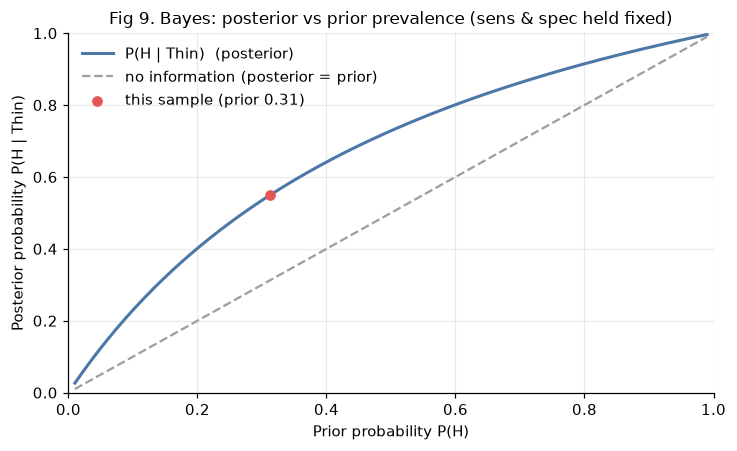

In [33]:
def ppv(pi):
    return sens * pi / (sens * pi + (1 - spec) * (1 - pi))

def npv(pi):
    return spec * (1 - pi) / (spec * (1 - pi) + (1 - sens) * pi)

scen = pd.DataFrame({"Prior P(H)": [0.05, 0.10, 0.20, prior]}, index=["hypothetical 5%", "hypothetical 10%", "hypothetical 20%", "this sample"])
scen["P(H | Thin) = PPV"] = scen["Prior P(H)"].map(ppv)
scen["P(not H | not Thin) = NPV"] = scen["Prior P(H)"].map(npv)
scen["PPV / prior"] = scen["P(H | Thin) = PPV"] / scen["Prior P(H)"]
display(scen)

fig, ax = plt.subplots(figsize=(6.8, 4.2))
pis = np.linspace(0.01, 0.99, 200)
ax.plot(pis, ppv(pis), color=BLUE, lw=2, label="P(H | Thin)  (posterior)")
ax.plot(pis, pis, color=GREY, ls="--", label="no information (posterior = prior)")
ax.scatter([prior], [post], color=RED, zorder=5, label=f"this sample (prior {prior:.2f})")
ax.set(title="Fig 9. Bayes: posterior vs prior prevalence (sens & spec held fixed)",
       xlabel="Prior probability P(H)", ylabel="Posterior probability P(H | Thin)", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False)
save_fig("fig9_bayes_posterior_vs_prior")

<div dir="rtl">

**تفسیر.** منحنی آبی بالای خط‌چین خاکستری است: Thin همیشه احتمال را بالا می‌برد؛ ولی وقتی شیوع واقعی پایین است (مثلاً ۵٪)، حتی با شاهد Thin احتمال پسین هنوز **پایین** می‌ماند — بسیاری از دارندگان Thin در جمعیت عمومی مختل نیستند. این همان پدیده‌ی **نرخ پایه** است و دلیل دیگری است که نتایج این پروژه را نباید به جمعیت عمومی تعمیم داد.

## ۱۰.۲ کاربرد دوم: ترکیب گروه Thin بر حسب شدت CDR
بیز را برای محاسبه‌ی «از میان دارندگان Thin، سهم هر گروه CDR چقدر است؟» هم می‌توان به کار برد:
$P(G\mid T)=\dfrac{P(T\mid G)P(G)}{P(T)}$

</div>

In [34]:
ok = df["CDR_group"].notna() & Thin.notna()
dfk = pd.DataFrame({"G": df.loc[ok, "CDR_group"], "T": Thin[ok].astype(bool)})
P_G = dfk["G"].value_counts(normalize=True).reindex(CDR_LABELS)                 # P(G)
P_T_given_G = dfk.groupby("G", observed=True)["T"].mean().reindex(CDR_LABELS)    # P(T | G)
P_T = dfk["T"].mean()
P_G_given_T_bayes = P_T_given_G * P_G / P_T
P_G_given_T_direct = dfk.loc[dfk["T"], "G"].value_counts(normalize=True).reindex(CDR_LABELS)
assert np.allclose(P_G_given_T_bayes, P_G_given_T_direct)

t102 = pd.DataFrame({"P(G) (prior)": P_G, "P(Thin | G)": P_T_given_G,
                     "P(G | Thin) (posterior)": P_G_given_T_bayes, "posterior / prior": P_G_given_T_bayes / P_G})
display(t102)
print(f"n = {int(ok.sum())} | P(Thin) = {P_T:.3f} | مجموع پسین‌ها = {P_G_given_T_bayes.sum():.3f}")
for g in CDR_LABELS:
    reg(f"Bayes: P(CDR group {g} | Thin)", round(P_G_given_T_bayes[g] * dfk['T'].sum()), int(dfk['T'].sum()))

,P(G) (prior),P(Thin | G),P(G | Thin) (posterior),posterior / prior
G,,,,
0,0.6152,0.1633,0.4020,0.6534
0.5-1.5,0.2320,0.2782,0.2582,1.1127
2-4.5,0.1136,0.5180,0.2353,2.0719
>=5,0.0392,0.6667,0.1046,2.6667


n = 1224 | P(Thin) = 0.250 | مجموع پسین‌ها = 1.000


<div dir="rtl">

**تفسیر.** ستون «posterior / prior» می‌گوید Thin سهم هر گروه را چند برابر کرده است: برای گروه‌های شدیدتر بیشتر از ۱ و برای گروه ۰ کمتر از ۱ انتظار می‌رود. باز هم یادآوری: بخش بزرگی از دارندگان Thin در گروه CDR=0 هستند چون آن گروه بزرگ‌ترین گروه است. پس «Thin» نشانگر قطعی بیماری نیست.

</div>

<div dir="rtl">

---
# ۱۱. جدول نهایی احتمال‌ها (خروجی فاز ۲)

همه‌ی احتمال‌هایی که در طول نوت‌بوک با برچسب ثبت شدند اینجا جمع می‌شوند. هر ردیف: برچسب، صورت (تعداد موافق)، مخرج و مقدار. جدول در `reports/tables/phase2_probability_table.csv` ذخیره می‌شود تا در گزارش `phase2.pdf` عیناً استفاده شود.

> **دو جدول:** (الف) احتمال‌ها؛ ردیف‌های «model» یا «expected» از مدل/فرمول آمده‌اند و صورت و مخرج ندارند. (ب) کمیت‌های غیراحتمالی (امید، واریانس، کوواریانس، همبستگی، $LR$) که در گزارش کنار جدول احتمال می‌آیند.

</div>

In [35]:
PT_df = pd.DataFrame(PT)
PT_df = PT_df.drop_duplicates(subset="Probability", keep="last").reset_index(drop=True)
PT_df["Value"] = PT_df["Value"].astype(float).round(4)

with pd.option_context("display.max_rows", 300, "display.max_colwidth", 80):
    display(PT_df)

OT_df = pd.DataFrame(OT).drop_duplicates(subset="Quantity", keep="last").reset_index(drop=True)
print("\nکمیت‌های غیراحتمالی (امید، کوواریانس، ...):")
display(OT_df)

PT_df.to_csv(TAB / "phase2_probability_table.csv", index=False)
OT_df.to_csv(TAB / "phase2_other_quantities.csv", index=False)
t5.to_csv(TAB / "phase2_independence_table.csv")
t41.to_csv(TAB / "phase2_P_thin_given_cdr_group.csv")
t83.to_csv(TAB / "phase2_total_expectation_by_cdr_group.csv")
t9.to_csv(TAB / "phase2_covariance_table.csv")
print(f"\nذخیره شد: {len(PT_df)} ردیف احتمال و {len(OT_df)} کمیت دیگر در {TAB}")

,Probability,Numerator,Denominator,Value
0,P(CDR+) [all participants with CDRSUM],480.0000,"1,237.0000",0.3880
1,P(Thin) [all participants with entorhinal MRI],306.0000,"1,224.0000",0.2500
2,P(CDR group 0 ∩ Thin),123.0000,"1,224.0000",0.1005
3,P(CDR group 0.5-1.5 ∩ Thin),79.0000,"1,224.0000",0.0645
4,P(CDR group 2-4.5 ∩ Thin),72.0000,"1,224.0000",0.0588
5,P(CDR group >=5 ∩ Thin),32.0000,"1,224.0000",0.0261
6,P(CDR+ ∩ Thin),183.0000,"1,224.0000",0.1495
7,P(CDR+) [all participants],480.0000,"1,237.0000",0.3880
8,P(Dx_imp ∩ Thin),168.0000,"1,224.0000",0.1373
9,P(Dx_imp) [all participants],390.0000,"1,237.0000",0.3153



کمیت‌های غیراحتمالی (امید، کوواریانس، ...):


,Quantity,Value,Unit
0,"Var(J) observed / Var Binomial(10, p̄)",5.5477,ratio
1,E[CDRSUM],0.8222,points
2,Var(CDRSUM) [n],2.9663,points²
3,"eta² = Var(E[X|G]) / Var(X) (CDR group, entor...",0.1079,fraction
4,"Cov(CDRSUM, TH_ENTORHINAL)",-0.1808,points·mm
5,"Pearson r(CDRSUM, TH_ENTORHINAL)",-0.3100,
6,"Spearman rho(CDRSUM, TH_ENTORHINAL)",-0.3051,
7,"Partial rank-corr(CDRSUM, entorhinal | age, se...",-0.2737,
8,Bayes: LR+ = sensitivity / (1 − specificity),2.6834,
9,Bayes: LR−,0.6700,



ذخیره شد: 51 ردیف احتمال و 10 کمیت دیگر در /home/parnia/nacc_project/reports/tables
